# Credit Card Fraud Detection Using Machine Learning

## Notebook 02: Feature Engineering and Preprocessing

## 1. Dataset Loading and Modelling Population Definition

In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load the dataset
df = pd.read_csv(
    '../data/raw/credit_card_fraud_drift_2026.csv'
)

In [3]:
# Create transaction-time eligible modelling dataset
model_df = df.loc[
    df['transaction_time_eligible'] == 1
].copy()

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)

Original dataset shape: (120000, 73)
Modelling dataset shape: (118107, 73)


In [4]:
# Verify target distribution
print("Binary Target Distribution:")
print(model_df['is_fraud'].value_counts())

print("\nBinary Target Percentage:")
print(
    model_df['is_fraud']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Binary Target Distribution:
is_fraud
0    108613
1      9494
Name: count, dtype: int64

Binary Target Percentage:
is_fraud
0    91.96
1     8.04
Name: proportion, dtype: float64


### Modelling Dataset and Target Distribution

The transaction-time eligible dataset contains 118,107 records after excluding 1,893 records identified as ineligible for transaction-time prediction.

The binary target variable, `is_fraud`, contains:

- Legitimate transactions (0): 108,613 (91.96%)
- Fraudulent transactions (1): 9,494 (8.04%)

The target distribution indicates class imbalance, with legitimate transactions representing the majority class.

This imbalance will be considered during model development and evaluation. Appropriate evaluation metrics and class-imbalance handling techniques will be explored in the modelling stage.

## 2. Candidate Predictor Selection and Feature Classification

In [5]:
# Define the target variable
target_column = 'is_fraud'

# Columns excluded from the predictor candidates
exclude_columns = [
    'is_fraud',
    'fraud_type',
    'transaction_time_target',
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id',
    'post_transaction_outcome',
    'fraud_amount_lost',
    'dispute_filed',
    'dispute_adjudicated_friendly_fraud',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime',
    'label_available',
    'label_delay_days',
    'pseudo_label',
    'drift_phase',
    'drift_phase_name',
    'days_into_phase',
    'dispute_regime',
    'drift_magnitude',
    'concept_drift_score',
    'population_shift_index',
    'covariate_shift_flag',
    'transaction_time_eligible',
    'synthetic_id_camouflage_score',
    'transaction_datetime'
]

# Create the candidate predictor list
candidate_columns = [
    col for col in model_df.columns
    if col not in exclude_columns
]

# Separate target and candidate predictors
y = model_df[target_column].copy()
X_candidates = model_df[candidate_columns].copy()

print("Target shape:", y.shape)
print("Candidate predictor shape:", X_candidates.shape)
print("\nNumber of candidate predictors:", len(candidate_columns))
print("\nCandidate predictors:")
print(candidate_columns)

Target shape: (118107,)
Candidate predictor shape: (118107, 45)

Number of candidate predictors: 45

Candidate predictors:
['month', 'week_of_year', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velo

In [6]:
# Check the data types of candidate predictors
X_candidates.dtypes.value_counts()

int64      25
float64    11
str         9
Name: count, dtype: int64

In [7]:
# Identify numerical features
numerical_features = X_candidates.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical features
categorical_features = X_candidates.select_dtypes(
    include=['str', 'object', 'category']
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 36
Categorical features: 9

Numerical columns:
['month', 'week_of_year', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'is_weekend', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pos_entry_fallback', 'pin_retry_count_24h']

Categorical columns:
['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_country', 'transaction_ch

In [8]:
# Identify numerical features containing only 0 and 1
binary_features = [
    col for col in numerical_features
    if set(X_candidates[col].dropna().unique()).issubset({0, 1})
]

print("Number of binary features:", len(binary_features))
print("\nBinary features:")
print(binary_features)

Number of binary features: 10

Binary features:
['card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'is_weekend', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'pos_entry_fallback']


In [9]:
# Define the count-based numerical features
count_features = [
    'num_cards_held',
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'num_declined_last_30d',
    'num_chargebacks_ever',
    'failed_auth_attempts_24h',
    'merchant_velocity_24h',
    'pin_retry_count_24h'
]

print("Number of count-based features:", len(count_features))
print("\nCount-based features:")
print(count_features)

Number of count-based features: 9

Count-based features:
['num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'merchant_velocity_24h', 'pin_retry_count_24h']


In [10]:
# Define temporal numerical features
temporal_features = [
    'month',
    'week_of_year',
    'transaction_hour'
]

print("Number of temporal features:", len(temporal_features))
print("\nTemporal features:")
print(temporal_features)

Number of temporal features: 3

Temporal features:
['month', 'week_of_year', 'transaction_hour']


In [11]:
# Define continuous numerical features
continuous_features = [
    col for col in numerical_features
    if col not in binary_features
    and col not in count_features
    and col not in temporal_features
]

print("Number of continuous features:", len(continuous_features))
print("\nContinuous features:")
print(continuous_features)

Number of continuous features: 14

Continuous features:
['transaction_amount', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'prior_dispute_ratio_90d']


In [12]:
# Combine all numerical feature groups
all_numerical_groups = (
    binary_features
    + count_features
    + temporal_features
    + continuous_features
)

print("Total numerical features:", len(numerical_features))
print("Features across all groups:", len(all_numerical_groups))
print("Unique grouped features:", len(set(all_numerical_groups)))

print(
    "\nAll numerical features accounted for:",
    set(numerical_features) == set(all_numerical_groups)
)

Total numerical features: 36
Features across all groups: 36
Unique grouped features: 36

All numerical features accounted for: True


## 4. Feature Availability, Source Verification and Timestamp Analysis

In [13]:
# Display unique values in each categorical feature
for col in categorical_features:
    print(f"\n{col}:")
    print(X_candidates[col].value_counts(dropna=False))


merchant_category:
merchant_category
retail             20975
grocery            19075
restaurant         16185
fuel               12602
electronics        10062
digital_goods       9688
subscription        8915
health              8315
travel              7494
cash_withdrawal     4796
Name: count, dtype: int64

merchant_country:
merchant_country
US    57223
IN    11401
GB    10446
CA     7405
DE     7058
FR     5307
IE     4515
ES     3752
NL     3132
SG     3065
NG     2686
BR     2117
Name: count, dtype: int64

transaction_day_of_week:
transaction_day_of_week
Tuesday      17181
Thursday     17086
Sunday       16989
Monday       16924
Friday       16817
Saturday     16773
Wednesday    16337
Name: count, dtype: int64

customer_gender:
customer_gender
F          57574
M          55065
unknown     3240
X           2228
Name: count, dtype: int64

customer_country:
customer_country
US    47845
IN    14487
GB    11970
CA     7883
DE     6833
IE     6004
FR     5831
SG     3596
NG     3490

In [14]:
# Check missing values in candidate predictors
missing_values = X_candidates.isnull().sum()

print("Total missing values:", missing_values.sum())
print("\nFeatures with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Features with missing values:
Series([], dtype: int64)


In [15]:
# Check duplicate records in the modelling dataset
# Check duplicate rows
duplicate_rows = model_df.duplicated().sum()

# Check duplicate transaction IDs
duplicate_ids = model_df['transaction_id'].duplicated().sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate transaction IDs:", duplicate_ids)

Duplicate rows: 0
Duplicate transaction IDs: 0


In [16]:
# Generate descriptive statistics for numerical features
numerical_summary = X_candidates[numerical_features].describe().T

numerical_summary.round(2)

,count,mean,std,min,25%,50%,75%,max
month,118107.0,3.51,1.71,1.00,2.00,4.00,5.00,6.00
week_of_year,118107.0,13.87,7.47,1.00,7.00,14.00,20.00,27.00
transaction_amount,118107.0,46.07,36.76,1.50,22.63,36.13,57.52,1030.59
transaction_hour,118107.0,11.47,6.91,0.00,5.00,11.00,17.00,23.00
card_present,118107.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
customer_age,118107.0,41.86,13.44,18.00,32.00,42.00,51.00,90.00
account_age_days,118107.0,831.31,907.11,15.00,309.00,531.00,989.00,24603.00
credit_limit,118107.0,6720.07,5459.96,500.00,3202.08,5197.00,8430.48,73621.86
credit_score,118107.0,688.81,63.99,300.00,646.00,689.00,732.00,850.00
num_cards_held,118107.0,2.82,1.35,1.00,2.00,3.00,4.00,8.00


In [17]:
# Calculate skewness for numerical features
skewness = X_candidates[numerical_features].skew()

# Sort features by absolute skewness
skewness = skewness.reindex(
    skewness.abs().sort_values(ascending=False).index
)

skewness.round(2)

amount_last_24h                14.79
num_declined_last_30d           8.47
prior_dispute_ratio_90d         8.07
distance_from_home_km           7.60
pin_retry_count_24h             7.03
num_chargebacks_ever            6.83
distance_from_last_tx_km        6.68
transactions_last_1h            6.32
amount_last_1h                  5.95
merchant_velocity_24h           5.60
transactions_last_24h           5.58
failed_auth_attempts_24h        4.81
amount_vs_avg_ratio             4.46
account_age_days                4.36
account_profile_change_7d       4.31
avg_transaction_amount_30d      3.99
billing_shipping_mismatch       3.59
high_risk_country               3.49
transaction_amount              3.14
credit_limit                    2.64
transactions_last_7d            2.59
device_change_7d                2.42
international_transaction       2.35
std_transaction_amount_30d      1.94
pos_entry_fallback              1.62
is_weekend                      0.95
used_pin                        0.79
n

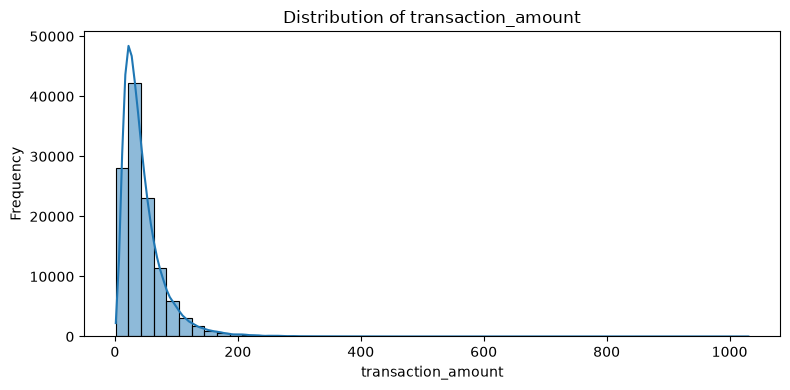

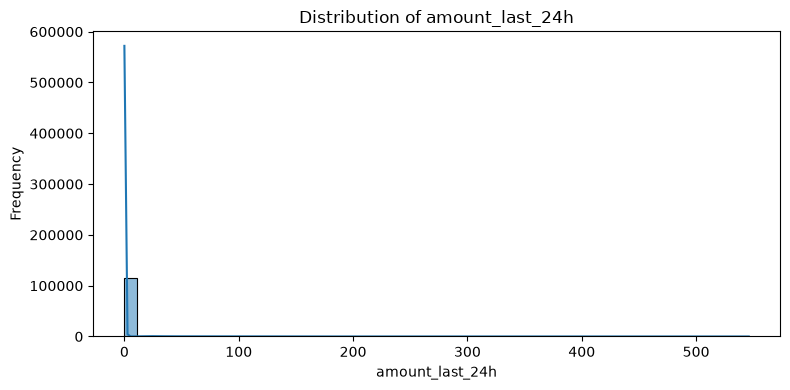

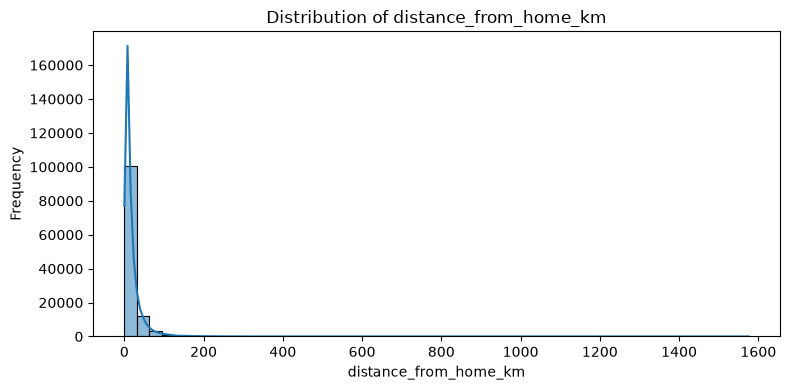

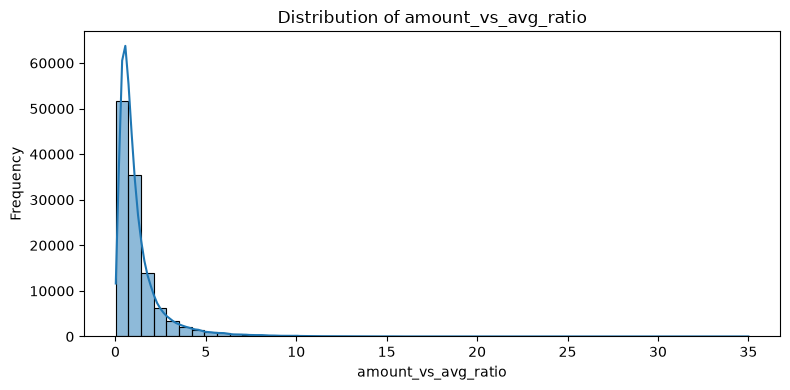

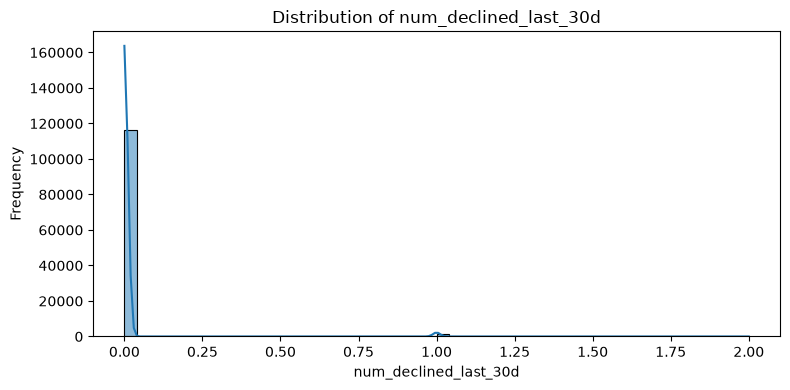

In [18]:
# Visualize selected numerical distributions
import matplotlib.pyplot as plt
import seaborn as sns

selected_skewed_features = [
    'transaction_amount',
    'amount_last_24h',
    'distance_from_home_km',
    'amount_vs_avg_ratio',
    'num_declined_last_30d'
]

for col in selected_skewed_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(X_candidates[col], bins=50, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

In [19]:
# Calculate the percentage of zero values
zero_percentage = (
    X_candidates[numerical_features]
    .eq(0)
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Features with the highest zero percentages:")
print(zero_percentage.head(15).round(2))

Features with the highest zero percentages:
num_declined_last_30d        98.63
amount_last_24h              97.81
num_chargebacks_ever         95.38
account_profile_change_7d    95.35
transactions_last_1h         94.38
billing_shipping_mismatch    93.69
high_risk_country            93.39
amount_last_1h               91.85
pin_retry_count_24h          91.11
prior_dispute_ratio_90d      90.37
transactions_last_24h        90.26
device_change_7d             88.52
international_transaction    88.10
transactions_last_7d         85.90
failed_auth_attempts_24h     82.14
dtype: float64


In [20]:
# Count unique categories in each categorical feature
categorical_cardinality = (
    X_candidates[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

print("Unique categories per feature:")
print(categorical_cardinality)

Unique categories per feature:
merchant_country           12
customer_country           12
merchant_category          10
transaction_day_of_week     7
email_domain                7
browser                     6
device_type                 5
transaction_channel         5
customer_gender             4
dtype: int64


In [21]:
# Review features requiring timing verification
# Historical features requiring timing verification
historical_features_to_verify = [
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'amount_last_1h',
    'amount_last_24h',
    'days_since_last_transaction',
    'amount_vs_avg_ratio',
    'avg_transaction_amount_30d',
    'std_transaction_amount_30d',
    'num_declined_last_30d',
    'num_chargebacks_ever',
    'failed_auth_attempts_24h',
    'device_change_7d',
    'account_profile_change_7d',
    'merchant_velocity_24h',
    'prior_dispute_ratio_90d',
    'pin_retry_count_24h'
]

print("Historical features requiring verification:",
      len(historical_features_to_verify))

print("\nFeatures:")
print(historical_features_to_verify)

Historical features requiring verification: 17

Features:
['transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pin_retry_count_24h']


In [22]:
# Geographic features requiring source and timing verification
geographic_features_to_verify = [
    'distance_from_home_km',
    'distance_from_last_tx_km'
]

print("Geographic features requiring verification:",
      len(geographic_features_to_verify))

print("\nFeatures:")
print(geographic_features_to_verify)

Geographic features requiring verification: 2

Features:
['distance_from_home_km', 'distance_from_last_tx_km']


In [23]:
# Identify features requiring source verification
# Transaction and account features requiring source verification
transaction_account_features = [
    'transaction_amount',
    'merchant_category',
    'merchant_country',
    'card_present',
    'customer_age',
    'customer_gender',
    'customer_country',
    'account_age_days',
    'credit_limit',
    'credit_score',
    'num_cards_held',
    'international_transaction',
    'high_risk_country',
    'used_chip',
    'used_pin',
    'transaction_channel',
    'device_type',
    'browser',
    'billing_shipping_mismatch',
    'email_domain',
    'pos_entry_fallback'
]

print("Features requiring source verification:",
      len(transaction_account_features))

print("\nFeatures:")
print(transaction_account_features)

Features requiring source verification: 21

Features:
['transaction_amount', 'merchant_category', 'merchant_country', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'billing_shipping_mismatch', 'email_domain', 'pos_entry_fallback']


In [24]:
# Combine all features requiring verification
features_requiring_verification = (
    historical_features_to_verify
    + geographic_features_to_verify
    + transaction_account_features
)

print("Historical features:", len(historical_features_to_verify))
print("Geographic features:", len(geographic_features_to_verify))
print("Transaction/account features:", len(transaction_account_features))

print("\nTotal features requiring verification:",
      len(features_requiring_verification))

print("Unique features:",
      len(set(features_requiring_verification)))

print(
    "\nAll 40 unverified features accounted for:",
    len(set(features_requiring_verification)) == 40
)

Historical features: 17
Geographic features: 2
Transaction/account features: 21

Total features requiring verification: 40
Unique features: 40

All 40 unverified features accounted for: True


In [25]:
# Create a summary of feature verification groups
verification_summary = pd.DataFrame({
    'Verification_Group': [
        'Available at transaction time',
        'Historical timing verification',
        'Source and timing verification',
        'Source verification'
    ],
    'Feature_Count': [
        5,
        len(historical_features_to_verify),
        len(geographic_features_to_verify),
        len(transaction_account_features)
    ]
})

verification_summary

,Verification_Group,Feature_Count
0,Available at transaction time,5
1,Historical timing verification,17
2,Source and timing verification,2
3,Source verification,21


In [26]:
# Identify timestamp-derived features
timestamp_features = [
    'month',
    'week_of_year',
    'transaction_hour',
    'transaction_day_of_week',
    'is_weekend'
]

# Display unique values for each feature
for col in timestamp_features:
    print(f"\n{col}:")
    print(sorted(model_df[col].unique()))


month:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

week_of_year:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27)]

transaction_hour:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]

transaction_day_of_week:
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

is_weekend:
[np.int64(0), np.int64(1)]


In [27]:
# Check month and week relationship
pd.crosstab(
    model_df['month'],
    model_df['week_of_year']
)

week_of_year,1,2,3,4,5,6,7,8,9,10,...,18,19,20,21,22,23,24,25,26,27
month,,,,,,,,,,,,,,,,,,,,,
1,2568,4641,4447,4625,3889,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,672,4490,4630,4589,3925,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,657,4629,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,2660,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,1996,4590,4655,4610,4552,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,4543,4546,4543,4573,1340


In [28]:
# Examine transaction-day distribution
model_df['transaction_day_of_week'].value_counts()

transaction_day_of_week
Tuesday      17181
Thursday     17086
Sunday       16989
Monday       16924
Friday       16817
Saturday     16773
Wednesday    16337
Name: count, dtype: int64

In [29]:
# Verify weekend feature consistency
pd.crosstab(
    model_df['transaction_day_of_week'],
    model_df['is_weekend']
)

is_weekend,0,1
transaction_day_of_week,,
Friday,16817,0
Monday,16924,0
Saturday,0,16773
Sunday,0,16989
Thursday,17086,0
Tuesday,17181,0
Wednesday,16337,0


In [30]:
# Inspect hour distribution
model_df['transaction_hour'].value_counts().sort_index()

transaction_hour
0     4986
1     4892
2     4966
3     4818
4     5013
5     4893
6     4940
7     4904
8     4977
9     5089
10    4922
11    4897
12    4892
13    4932
14    4973
15    4957
16    4833
17    5005
18    4874
19    4928
20    4860
21    4817
22    4869
23    4870
Name: count, dtype: int64

In [31]:
# Examine monthly transaction distribution
model_df['month'].value_counts().sort_index()

month
1    20170
2    18306
3    20141
4    19542
5    20403
6    19545
Name: count, dtype: int64

In [32]:
# Check target distribution across hours
hourly_fraud = (
    model_df.groupby('transaction_hour')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

hourly_fraud.columns = [
    'Transaction_Count',
    'Fraud_Count',
    'Fraud_Rate'
]

hourly_fraud['Fraud_Rate'] = (
    hourly_fraud['Fraud_Rate'] * 100
).round(2)

hourly_fraud

,Transaction_Count,Fraud_Count,Fraud_Rate
transaction_hour,,,
0,4986,389,7.80
1,4892,450,9.20
2,4966,422,8.50
3,4818,376,7.80
4,5013,387,7.72
5,4893,414,8.46
6,4940,380,7.69
7,4904,367,7.48
8,4977,392,7.88


In [33]:
# Examine weekday fraud rates
weekday_fraud = (
    model_df.groupby('transaction_day_of_week')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

weekday_fraud.columns = [
    'Transaction_Count',
    'Fraud_Count',
    'Fraud_Rate'
]

weekday_fraud['Fraud_Rate'] = (
    weekday_fraud['Fraud_Rate'] * 100
).round(2)

weekday_fraud

,Transaction_Count,Fraud_Count,Fraud_Rate
transaction_day_of_week,,,
Friday,16817,1329,7.90
Monday,16924,1358,8.02
Saturday,16773,1363,8.13
Sunday,16989,1370,8.06
Thursday,17086,1341,7.85
Tuesday,17181,1408,8.20
Wednesday,16337,1325,8.11


In [34]:
# Examine monthly fraud rates
monthly_fraud = (
    model_df.groupby('month')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

monthly_fraud.columns = [
    'Transaction_Count',
    'Fraud_Count',
    'Fraud_Rate'
]

monthly_fraud['Fraud_Rate'] = (
    monthly_fraud['Fraud_Rate'] * 100
).round(2)

monthly_fraud

,Transaction_Count,Fraud_Count,Fraud_Rate
month,,,
1,20170,1558,7.72
2,18306,1502,8.20
3,20141,1601,7.95
4,19542,1551,7.94
5,20403,1657,8.12
6,19545,1625,8.31


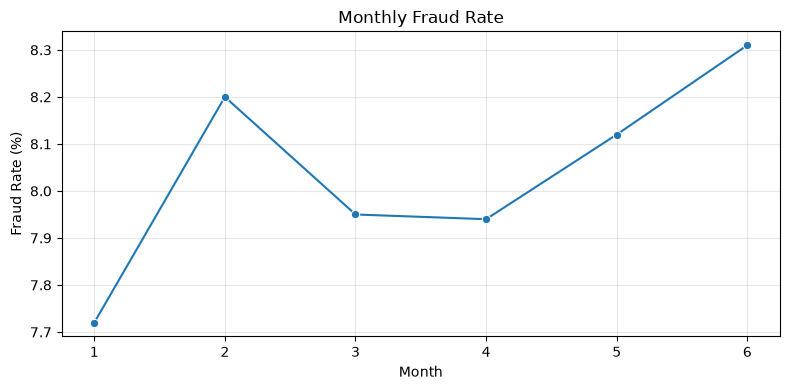

In [35]:
# Compare monthly fraud rates
plt.figure(figsize=(8, 4))

sns.lineplot(
    x=monthly_fraud.index,
    y=monthly_fraud['Fraud_Rate'],
    marker='o'
)

plt.title('Monthly Fraud Rate')
plt.xlabel('Month')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(1, 7))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
# Create the verified timestamp feature list
# Timestamp features verified as available at transaction time
verified_timestamp_features = [
    'month',
    'week_of_year',
    'transaction_hour',
    'transaction_day_of_week'
]

# Redundant feature identified during analysis
redundant_features = [
    'is_weekend'
]

print("Verified timestamp features:",
      len(verified_timestamp_features))

print(verified_timestamp_features)

print("\nRedundant features:")
print(redundant_features)

Verified timestamp features: 4
['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week']

Redundant features:
['is_weekend']


In [37]:
# Create an updated candidate feature set
X_revised = X_candidates.drop(
    columns=redundant_features
).copy()

print("Original candidate features:", X_candidates.shape[1])
print("Revised candidate features:", X_revised.shape[1])

print("\nRemoved features:", redundant_features)

Original candidate features: 45
Revised candidate features: 44

Removed features: ['is_weekend']


In [38]:
# Create a feature-level verification register
feature_status = {}

for col in verified_timestamp_features:
    feature_status[col] = 'Verified: transaction-time available'

for col in historical_features_to_verify:
    feature_status[col] = 'Pending: historical timing verification'

for col in geographic_features_to_verify:
    feature_status[col] = 'Pending: source and timing verification'

for col in transaction_account_features:
    feature_status[col] = 'Pending: source verification'

feature_status_df = pd.DataFrame(
    list(feature_status.items()),
    columns=['Feature', 'Verification_Status']
)

print("Total registered features:", len(feature_status_df))
print("\nVerification status summary:")
print(feature_status_df['Verification_Status'].value_counts())

feature_status_df.head(10)

Total registered features: 44

Verification status summary:
Verification_Status
Pending: source verification               21
Pending: historical timing verification    17
Verified: transaction-time available        4
Pending: source and timing verification     2
Name: count, dtype: int64


,Feature,Verification_Status
0,month,Verified: transaction-time available
1,week_of_year,Verified: transaction-time available
2,transaction_hour,Verified: transaction-time available
3,transaction_day_of_week,Verified: transaction-time available
4,transactions_last_1h,Pending: historical timing verification
5,transactions_last_24h,Pending: historical timing verification
6,transactions_last_7d,Pending: historical timing verification
7,amount_last_1h,Pending: historical timing verification
8,amount_last_24h,Pending: historical timing verification
9,days_since_last_transaction,Pending: historical timing verification


In [39]:
# Separate features according to verification status
verified_features = feature_status_df.loc[
    feature_status_df['Verification_Status']
    == 'Verified: transaction-time available',
    'Feature'
].tolist()

pending_features = feature_status_df.loc[
    feature_status_df['Verification_Status'] !=
    'Verified: transaction-time available',
    'Feature'
].tolist()

print("Verified features:", len(verified_features))
print(verified_features)

print("\nPending features:", len(pending_features))
print(pending_features)

print("\nTotal accounted for:",
      len(verified_features) + len(pending_features))

Verified features: 4
['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week']

Pending features: 40
['transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pin_retry_count_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'transaction_amount', 'merchant_category', 'merchant_country', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'billing_shipping_mismatch', 'email_domain', 'pos_entry_fallback']

Total acc

In [40]:
# Conservative baseline using verified features
X_verified_baseline = X_revised[verified_features].copy()

# Expanded experimental candidates requiring verification
X_pending_review = X_revised[pending_features].copy()

print("Verified baseline shape:",
      X_verified_baseline.shape)

print("Pending feature dataset shape:",
      X_pending_review.shape)

print("\nTotal feature columns:",
      X_verified_baseline.shape[1] + X_pending_review.shape[1])

Verified baseline shape: (118107, 4)
Pending feature dataset shape: (118107, 40)

Total feature columns: 44


## 5. Historical Feature Investigation and Reliability Assessment

In [41]:
# Display historical features and their verification status
historical_review = feature_status_df[
    feature_status_df['Feature'].isin(
        historical_features_to_verify
    )
].copy()

historical_review

,Feature,Verification_Status
4,transactions_last_1h,Pending: historical timing verification
5,transactions_last_24h,Pending: historical timing verification
6,transactions_last_7d,Pending: historical timing verification
7,amount_last_1h,Pending: historical timing verification
8,amount_last_24h,Pending: historical timing verification
9,days_since_last_transaction,Pending: historical timing verification
10,amount_vs_avg_ratio,Pending: historical timing verification
11,avg_transaction_amount_30d,Pending: historical timing verification
12,std_transaction_amount_30d,Pending: historical timing verification
13,num_declined_last_30d,Pending: historical timing verification


In [42]:
# Inspect historical feature examples
historical_sample = model_df[
    ['transaction_datetime'] + historical_features_to_verify
].head(10)

historical_sample

,transaction_datetime,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,amount_vs_avg_ratio,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,failed_auth_attempts_24h,device_change_7d,account_profile_change_7d,merchant_velocity_24h,prior_dispute_ratio_90d,pin_retry_count_24h
0,2026-01-01 00:00:00,0,0,0,0.0,0.0,90.0,0.3268,50.0,20.0,0,0,1,0,0,0,0.0,0
1,2026-01-01 00:00:00,0,0,0,0.0,0.0,90.0,0.5576,50.0,20.0,0,0,0,0,0,0,0.0,0
2,2026-01-01 00:03:00,0,0,0,0.0,0.0,90.0,0.4942,50.0,20.0,0,0,2,0,0,0,0.0,0
3,2026-01-01 00:04:00,0,0,0,0.0,0.0,90.0,1.2414,50.0,20.0,0,0,1,0,0,0,0.0,0
4,2026-01-01 00:05:00,0,0,0,0.0,0.0,90.0,0.9246,50.0,20.0,0,0,0,0,0,0,0.0,1
5,2026-01-01 00:05:00,0,0,0,0.0,0.0,90.0,0.1756,50.0,20.0,0,0,0,0,0,0,0.0,1
6,2026-01-01 00:05:00,0,0,0,0.0,0.0,90.0,0.5254,50.0,20.0,0,0,0,0,0,0,0.0,0
7,2026-01-01 00:07:00,0,0,0,0.0,0.0,90.0,0.5674,50.0,20.0,0,0,0,0,0,0,0.0,0
8,2026-01-01 00:11:00,0,0,0,0.0,0.0,90.0,0.7064,50.0,20.0,0,0,0,0,0,0,0.0,0
9,2026-01-01 00:12:00,0,0,0,0.0,0.0,90.0,0.6232,50.0,20.0,0,0,0,1,0,0,0.0,0


In [43]:
# Check chronological ordering
timestamps = pd.to_datetime(model_df['transaction_datetime'])

print("First transaction:", timestamps.min())
print("Last transaction:", timestamps.max())

print("\nDataset already sorted chronologically:",
      timestamps.is_monotonic_increasing)

print("\nNumber of unique timestamps:",
      timestamps.nunique())

First transaction: 2026-01-01 00:00:00
Last transaction: 2026-06-30 23:58:00

Dataset already sorted chronologically: True

Number of unique timestamps: 94721


In [44]:
# Examine most frequent values in selected historical features
selected_features = [
    'days_since_last_transaction',
    'avg_transaction_amount_30d',
    'std_transaction_amount_30d'
]

for col in selected_features:
    print(f"\nMost frequent values in {col}:")
    print(model_df[col].value_counts().head(10))


Most frequent values in days_since_last_transaction:
days_since_last_transaction
90.0    30858
0.5       590
0.6       111
0.7       106
1.4        93
1.5        90
0.8        89
0.9        83
2.3        82
1.0        82
Name: count, dtype: int64

Most frequent values in avg_transaction_amount_30d:
avg_transaction_amount_30d
50.00    65057
21.12       23
23.27       22
30.30       21
32.46       21
17.26       21
32.94       20
28.61       20
30.26       20
22.96       20
Name: count, dtype: int64

Most frequent values in std_transaction_amount_30d:
std_transaction_amount_30d
20.00    65047
0.00     37967
1.20        17
2.80        16
1.70        16
9.72        15
1.30        15
0.02        14
1.21        14
5.94        13
Name: count, dtype: int64


In [45]:
# Check frequency of repeated-value combinations

default_pattern = (
    (model_df['days_since_last_transaction'] == 90) &
    (model_df['avg_transaction_amount_30d'] == 50) &
    (model_df['std_transaction_amount_30d'] == 20)
)

print("Records containing all three repeated values:",
      default_pattern.sum())

print("\nPercentage of modelling dataset:",
      round(default_pattern.mean() * 100, 2), "%")

Records containing all three repeated values: 30857

Percentage of modelling dataset: 26.13 %


In [46]:
# Compare historical transaction counts across the repeated-value pattern

history_columns = [
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d'
]

print("Historical transaction counts when all three repeated values occur:")
print(model_df.loc[default_pattern, history_columns].describe())

print("\nHistorical transaction counts when the pattern does not occur:")
print(model_df.loc[~default_pattern, history_columns].describe())

Historical transaction counts when all three repeated values occur:
       transactions_last_1h  transactions_last_24h  transactions_last_7d
count          30857.000000           30857.000000               30857.0
mean               0.000065               0.000324                   0.0
std                0.011386               0.056928                   0.0
min                0.000000               0.000000                   0.0
25%                0.000000               0.000000                   0.0
50%                0.000000               0.000000                   0.0
75%                0.000000               0.000000                   0.0
max                2.000000              10.000000                   0.0

Historical transaction counts when the pattern does not occur:
       transactions_last_1h  transactions_last_24h  transactions_last_7d
count          87250.000000           87250.000000          87250.000000
mean               0.174842               0.556791              0

In [47]:
# Compare fraud distribution across the repeated-value pattern

pattern_target = pd.crosstab(
    default_pattern,
    y,
    normalize='index'
).mul(100).round(2)

pattern_target.columns = ['Legitimate (%)', 'Fraud (%)']
pattern_target.index = [
    'Pattern absent',
    'All three repeated values present'
]

pattern_target

,Legitimate (%),Fraud (%)
Pattern absent,89.12,10.88
All three repeated values present,100.00,0.00


In [48]:
# Examine the relationship between the repeated-value pattern and fraud type

pattern_fraud_types = pd.crosstab(
    default_pattern,
    model_df['fraud_type']
)

pattern_fraud_types

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
row_0,,,,,
False,2570,2879,1898,77757,2146
True,1,0,0,30856,0


In [49]:
# Examine the repeated-value pattern across transaction months

pattern_by_month = pd.crosstab(
    model_df['month'],
    default_pattern,
    margins=True
)

pattern_by_month.columns = [
    'Pattern absent',
    'All three values present',
    'Total'
]

pattern_by_month

,Pattern absent,All three values present,Total
month,,,
1,6696,13474,20170
2,11990,6316,18306
3,16461,3680,20141
4,17017,2525,19542
5,17924,2479,20403
6,17162,2383,19545
All,87250,30857,118107


In [50]:
# Calculate monthly frequency of the repeated-value pattern

monthly_pattern_rate = (
    model_df.assign(default_pattern=default_pattern)
    .groupby('month')['default_pattern']
    .agg(['sum', 'count', 'mean'])
)

monthly_pattern_rate.columns = [
    'Pattern_Count',
    'Total_Transactions',
    'Pattern_Percentage'
]

monthly_pattern_rate['Pattern_Percentage'] = (
    monthly_pattern_rate['Pattern_Percentage'] * 100
).round(2)

monthly_pattern_rate

,Pattern_Count,Total_Transactions,Pattern_Percentage
month,,,
1,13474,20170,66.80
2,6316,18306,34.50
3,3680,20141,18.27
4,2525,19542,12.92
5,2479,20403,12.15
6,2383,19545,12.19


In [51]:
# Compare monthly fraud rates across the two pattern groups

monthly_group_fraud = (
    model_df.assign(default_pattern=default_pattern)
    .groupby(['month', 'default_pattern'])['is_fraud']
    .agg(['count', 'sum', 'mean'])
    .reset_index()
)

monthly_group_fraud['fraud_rate_pct'] = (
    monthly_group_fraud['mean'] * 100
).round(2)

monthly_group_fraud

,month,default_pattern,count,sum,mean,fraud_rate_pct
0,1,False,6696,1557,0.232527,23.25
1,1,True,13474,1,0.000074,0.01
2,2,False,11990,1502,0.125271,12.53
3,2,True,6316,0,0.000000,0.00
4,3,False,16461,1601,0.097260,9.73
5,3,True,3680,0,0.000000,0.00
6,4,False,17017,1551,0.091144,9.11
7,4,True,2525,0,0.000000,0.00
8,5,False,17924,1657,0.092446,9.24
9,5,True,2479,0,0.000000,0.00


In [52]:
# Calculate overall monthly fraud rates

monthly_fraud_summary = (
    model_df.groupby('month')['is_fraud']
    .agg(['count', 'sum', 'mean'])
)

monthly_fraud_summary.columns = [
    'Total_Transactions',
    'Fraud_Count',
    'Fraud_Rate'
]

monthly_fraud_summary['Fraud_Rate'] = (
    monthly_fraud_summary['Fraud_Rate'] * 100
).round(2)

monthly_fraud_summary

,Total_Transactions,Fraud_Count,Fraud_Rate
month,,,
1,20170,1558,7.72
2,18306,1502,8.20
3,20141,1601,7.95
4,19542,1551,7.94
5,20403,1657,8.12
6,19545,1625,8.31


In [53]:
# Investigate frequent values in other historical features

remaining_historical_features = [
    col for col in historical_features_to_verify
    if col not in [
        'days_since_last_transaction',
        'avg_transaction_amount_30d',
        'std_transaction_amount_30d'
    ]
]

for col in remaining_historical_features:
    print(f"\n{col}:")
    print(model_df[col].value_counts().head(5))


transactions_last_1h:
transactions_last_1h
0    111474
1      2628
2      1690
3      1083
4       606
Name: count, dtype: int64

transactions_last_24h:
transactions_last_24h
0    106601
1      3816
2      1477
3      1226
4       967
Name: count, dtype: int64

transactions_last_7d:
transactions_last_7d
0    101451
1     15361
2      1232
3        58
4         5
Name: count, dtype: int64

amount_last_1h:
amount_last_1h
0.00      108485
0.50        1589
97.00          4
101.45         4
32.99          4
Name: count, dtype: int64

amount_last_24h:
amount_last_24h
0.00     115520
15.01         4
21.37         4
25.26         4
48.98         4
Name: count, dtype: int64

amount_vs_avg_ratio:
amount_vs_avg_ratio
0.300    444
0.500    293
0.800    231
1.000     60
0.454     31
Name: count, dtype: int64

num_declined_last_30d:
num_declined_last_30d
0    116484
1      1614
2         9
Name: count, dtype: int64

num_chargebacks_ever:
num_chargebacks_ever
0    112650
1      4310
2       742
3   

In [54]:
# Examine chargeback counts across fraud categories

chargeback_analysis = pd.crosstab(
    model_df['num_chargebacks_ever'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

chargeback_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
num_chargebacks_ever,,,,,
0,0.47,2.07,1.42,94.51,1.54
1,23.87,12.67,7.01,49.37,7.08
2,87.87,0.00,0.00,3.37,8.76
3,90.48,0.00,0.00,0.00,9.52
4,90.20,0.00,0.00,0.00,9.80


In [55]:
# Examine chargeback counts and fraud-category counts

chargeback_counts = pd.crosstab(
    model_df['num_chargebacks_ever'],
    model_df['fraud_type']
)

chargeback_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
num_chargebacks_ever,,,,,
0,524,2333,1596,106460,1737
1,1029,546,302,2128,305
2,652,0,0,25,65
3,228,0,0,0,24
4,138,0,0,0,15


In [56]:
# Examine chargeback-count distribution across months

monthly_chargebacks = pd.crosstab(
    model_df['month'],
    model_df['num_chargebacks_ever']
)

monthly_chargebacks

num_chargebacks_ever,0,1,2,3,4
month,,,,,
1,19498,490,111,41,30
2,17530,624,97,36,19
3,19136,802,139,37,27
4,18574,789,119,42,18
5,19409,785,131,49,29
6,18503,820,145,47,30


In [57]:
# Examine prior dispute ratios across fraud categories

dispute_ratio_analysis = pd.crosstab(
    model_df['prior_dispute_ratio_90d'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

dispute_ratio_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
prior_dispute_ratio_90d,,,,,
0.0000,0.01,0.03,0.18,99.75,0.04
0.0010,3.74,13.61,51.70,0.00,30.95
0.0020,7.27,15.00,37.73,0.00,40.00
0.0030,8.48,19.20,24.11,0.00,48.21
0.0040,7.89,20.18,25.44,0.00,46.49
...,...,...,...,...,...
0.6667,0.00,0.00,0.00,100.00,0.00
0.7050,100.00,0.00,0.00,0.00,0.00
0.7120,100.00,0.00,0.00,0.00,0.00


In [58]:
# Group prior dispute ratios into ranges

ratio_bins = [
    -0.001, 0,
    0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 1.00
]

ratio_labels = [
    '0',
    '(0, 0.01]',
    '(0.01, 0.05]',
    '(0.05, 0.10]',
    '(0.10, 0.25]',
    '(0.25, 0.50]',
    '(0.50, 0.75]',
    '(0.75, 1.00]'
]

ratio_groups = pd.cut(
    model_df['prior_dispute_ratio_90d'],
    bins=ratio_bins,
    labels=ratio_labels
)

ratio_group_analysis = pd.crosstab(
    ratio_groups,
    model_df['fraud_type'],
    margins=True
)

ratio_group_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity,All
prior_dispute_ratio_90d,,,,,,
0,7,29,188,106460,47,106731
"(0, 0.01]",160,394,622,0,1083,2259
"(0.01, 0.05]",326,1117,679,0,1016,3138
"(0.05, 0.10]",330,734,268,0,0,1332
"(0.10, 0.25]",1088,561,130,378,0,2157
"(0.25, 0.50]",601,44,11,1215,0,1871
"(0.50, 0.75]",59,0,0,8,0,67
"(0.75, 1.00]",0,0,0,552,0,552
All,2571,2879,1898,108613,2146,118107


In [59]:
# Examine merchant velocity across fraud categories

merchant_velocity_analysis = pd.crosstab(
    model_df['merchant_velocity_24h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

merchant_velocity_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
merchant_velocity_24h,,,,,
0,0.00,0.00,0.00,100.00,0.00
1,0.36,6.63,9.23,79.70,4.07
2,6.56,28.34,11.04,31.43,22.63
3,25.25,34.99,6.35,2.38,31.02
4,38.35,30.40,4.73,0.00,26.53
5,53.43,24.18,3.43,0.00,18.96
6,67.79,18.74,0.00,0.00,13.47
7,82.76,10.34,0.00,0.00,6.90
8,74.20,16.25,0.00,0.00,9.54


In [60]:
# Count transactions at each merchant velocity value

merchant_velocity_counts = pd.crosstab(
    model_df['merchant_velocity_24h'],
    model_df['fraud_type']
)

merchant_velocity_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
merchant_velocity_24h,,,,,
0,0,0,0,95184,0
1,57,1047,1457,12582,643
2,170,734,286,814,586
3,350,485,88,33,430
4,357,283,44,0,247
5,358,162,23,0,127
6,322,89,0,0,64
7,264,33,0,0,22
8,210,46,0,0,27


In [61]:
# Examine failed authentication attempts across fraud categories

failed_auth_analysis = pd.crosstab(
    model_df['failed_auth_attempts_24h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

failed_auth_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
failed_auth_attempts_24h,,,,,
0,0.02,1.12,0.97,96.22,1.67
1,2.28,6.01,3.84,86.20,1.67
2,26.24,18.31,9.37,42.36,3.72
3,57.57,21.12,8.07,6.67,6.57
4,71.33,16.31,4.94,0.33,7.08
5,78.66,14.33,0.00,0.00,7.01
6,84.09,6.82,0.00,0.00,9.09
7,80.00,8.89,0.00,0.00,11.11
8,88.71,9.68,0.00,0.00,1.61


In [62]:
# Count transactions at each failed authentication value

failed_auth_counts = pd.crosstab(
    model_df['failed_auth_attempts_24h'],
    model_df['fraud_type']
)

failed_auth_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
failed_auth_attempts_24h,,,,,
0,22,1083,939,93344,1623
1,377,993,634,14233,275
2,599,418,214,967,85
3,578,212,81,67,66
4,433,99,30,2,43
5,258,47,0,0,23
6,148,12,0,0,16
7,72,8,0,0,10
8,55,6,0,0,1


In [63]:
# Examine device changes across fraud categories

device_change_analysis = pd.crosstab(
    model_df['device_change_7d'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

device_change_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
device_change_7d,,,,,
0,0.26,2.14,1.70,94.19,1.70
1,16.92,4.74,0.86,74.74,2.74


In [64]:
# Count transactions by device-change status and fraud category

device_change_counts = pd.crosstab(
    model_df['device_change_7d'],
    model_df['fraud_type']
)

device_change_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
device_change_7d,,,,,
0,277,2237,1781,98482,1775
1,2294,642,117,10131,371


In [65]:
# Examine account profile changes across fraud categories

profile_change_analysis = pd.crosstab(
    model_df['account_profile_change_7d'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

profile_change_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
account_profile_change_7d,,,,,
0,0.63,2.16,1.65,94.77,0.78
1,33.89,8.09,0.75,34.27,23.00


In [66]:
# Count transactions by account profile-change status

profile_change_counts = pd.crosstab(
    model_df['account_profile_change_7d'],
    model_df['fraud_type']
)

profile_change_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
account_profile_change_7d,,,,,
0,710,2435,1857,106731,883
1,1861,444,41,1882,1263


In [67]:
# Examine PIN retry counts across fraud categories

pin_retry_analysis = pd.crosstab(
    model_df['pin_retry_count_24h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

pin_retry_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
pin_retry_count_24h,,,,,
0,0.70,2.43,0.00,95.07,1.81
1,14.33,2.94,1.35,79.16,2.22
2,43.55,4.20,31.58,17.52,3.15
3,28.91,0.00,70.76,0.34,0.00
4,15.04,0.00,84.96,0.00,0.00
5,15.27,0.00,84.73,0.00,0.00
6,0.00,0.00,100.00,0.00,0.00
7,0.00,0.00,100.00,0.00,0.00
8,0.00,0.00,100.00,0.00,0.00


In [68]:
# Count transactions at each PIN retry value

pin_retry_counts = pd.crosstab(
    model_df['pin_retry_count_24h'],
    model_df['fraud_type']
)

pin_retry_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
pin_retry_count_24h,,,,,
0,753,2611,0,102302,1944
1,1112,228,105,6142,172
2,415,40,301,167,30
3,172,0,421,2,0
4,68,0,384,0,0
5,51,0,283,0,0
6,0,0,167,0,0
7,0,0,103,0,0
8,0,0,72,0,0


In [69]:
# Examine declined transaction counts across fraud categories

declined_analysis = pd.crosstab(
    model_df['num_declined_last_30d'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

declined_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
num_declined_last_30d,,,,,
0,2.18,2.44,1.61,91.97,1.80
1,2.04,2.42,1.49,91.33,2.73
2,0.00,11.11,0.00,88.89,0.00


In [70]:
# Count transactions at each declined-transaction value

declined_counts = pd.crosstab(
    model_df['num_declined_last_30d'],
    model_df['fraud_type']
)

declined_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
num_declined_last_30d,,,,,
0,2538,2839,1874,107131,2102
1,33,39,24,1474,44
2,0,1,0,8,0


In [71]:
# Examine transaction counts in the previous hour across fraud categories

transactions_1h_analysis = pd.crosstab(
    model_df['transactions_last_1h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

transactions_1h_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_1h,,,,,
0,0.07,0.38,1.26,97.32,0.98
1,18.53,40.79,14.88,4.87,20.93
2,36.86,42.37,4.85,0.00,15.92
3,52.26,34.44,2.12,0.00,11.17
4,60.56,28.38,0.00,0.00,11.06
5,67.74,23.75,0.00,0.00,8.50
6,65.93,25.27,0.00,0.00,8.79
7,100.00,0.00,0.00,0.00,0.00
8,100.00,0.00,0.00,0.00,0.00


In [72]:
# Count transactions at each previous-hour transaction value

transactions_1h_counts = pd.crosstab(
    model_df['transactions_last_1h'],
    model_df['fraud_type']
)

transactions_1h_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_1h,,,,,
0,74,419,1402,108485,1094
1,487,1072,391,128,550
2,623,716,82,0,269
3,566,373,23,0,121
4,367,172,0,0,67
5,231,81,0,0,29
6,120,46,0,0,16
7,45,0,0,0,0
8,58,0,0,0,0


In [73]:
# Examine transaction counts in the previous 24 hours

transactions_24h_analysis = pd.crosstab(
    model_df['transactions_last_24h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

transactions_24h_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_24h,,,,,
0,0.00,0.00,0.35,99.65,0.00
1,0.00,5.92,20.41,61.98,11.69
2,0.14,33.58,28.17,1.62,36.49
3,1.55,46.49,15.42,0.00,36.54
4,7.03,54.60,7.86,0.00,30.51
5,21.19,51.96,4.72,0.00,22.13
6,36.76,41.18,4.25,0.00,17.81
7,54.95,33.33,0.00,0.00,11.72
8,66.19,25.20,0.00,0.00,8.61


In [74]:
# Count transactions at each previous-24-hour transaction value

transactions_24h_counts = pd.crosstab(
    model_df['transactions_last_24h'],
    model_df['fraud_type']
)

transactions_24h_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_24h,,,,,
0,0,0,377,106224,0
1,0,226,779,2365,446
2,2,496,416,24,539
3,19,570,189,0,448
4,68,528,76,0,295
5,157,385,35,0,164
6,225,252,26,0,109
7,272,165,0,0,58
8,323,123,0,0,42


In [75]:
# Examine transaction counts in the previous seven days

transactions_7d_analysis = pd.crosstab(
    model_df['transactions_last_7d'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

transactions_7d_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_7d,,,,,
0,2.16,2.42,1.60,91.99,1.82
1,2.21,2.56,1.63,91.88,1.72
2,2.84,2.35,1.54,91.07,2.19
3,3.45,0.00,1.72,87.93,6.90
4,0.00,0.00,0.00,100.00,0.00


In [76]:
# Count transactions at each previous-seven-day transaction value

transactions_7d_counts = pd.crosstab(
    model_df['transactions_last_7d'],
    model_df['fraud_type']
)

transactions_7d_counts

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
transactions_last_7d,,,,,
0,2195,2456,1628,93321,1851
1,339,394,250,14114,264
2,35,29,19,1122,27
3,2,0,1,51,4
4,0,0,0,5,0


In [77]:
# Examine previous-hour transaction amounts across fraud categories

amount_1h_analysis = pd.crosstab(
    model_df['amount_last_1h'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

amount_1h_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_1h,,,,,
0.00,0.00,0.00,0.00,100.0,0.00
0.50,21.84,28.01,21.96,0.0,28.19
0.53,0.00,0.00,0.00,0.0,100.00
0.56,0.00,100.00,0.00,0.0,0.00
0.59,0.00,0.00,100.00,0.0,0.00
...,...,...,...,...,...
642.19,100.00,0.00,0.00,0.0,0.00
649.81,100.00,0.00,0.00,0.0,0.00
651.22,100.00,0.00,0.00,0.0,0.00


In [78]:
# Group previous-hour transaction amounts into quantile-based ranges

amount_1h_bins = pd.qcut(
    model_df['amount_last_1h'],
    q=5,
    duplicates='drop'
)

amount_1h_binned_analysis = pd.crosstab(
    amount_1h_bins,
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

amount_1h_binned_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_1h,,,,,
"(-0.001, 693.62]",2.18,2.44,1.61,91.96,1.82


In [79]:
# Separate transactions with zero and nonzero previous-hour amounts

model_df['amount_last_1h_status'] = np.where(
    model_df['amount_last_1h'] == 0,
    'Zero',
    'Non-zero'
)

# Compare actual counts
amount_1h_status_counts = pd.crosstab(
    model_df['amount_last_1h_status'],
    model_df['fraud_type']
)

print("Actual Counts:")
display(amount_1h_status_counts)

# Compare category percentages
amount_1h_status_percentage = pd.crosstab(
    model_df['amount_last_1h_status'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

print("\nFraud Category Distribution (%):")
display(amount_1h_status_percentage)

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_1h_status,,,,,
Non-zero,2571,2879,1898,128,2146
Zero,0,0,0,108485,0



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_1h_status,,,,,
Non-zero,26.72,29.92,19.73,1.33,22.3
Zero,0.00,0.00,0.00,100.00,0.0


In [80]:
# Separate transactions with zero and nonzero previous-24-hour amounts

model_df['amount_last_24h_status'] = np.where(
    model_df['amount_last_24h'] == 0,
    'Zero',
    'Non-zero'
)

# Compare actual counts
amount_24h_status_counts = pd.crosstab(
    model_df['amount_last_24h_status'],
    model_df['fraud_type']
)

print("Actual Counts:")
display(amount_24h_status_counts)

# Compare category percentages
amount_24h_status_percentage = pd.crosstab(
    model_df['amount_last_24h_status'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

print("\nFraud Category Distribution (%):")
display(amount_24h_status_percentage)

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_24h_status,,,,,
Non-zero,48,70,33,2389,47
Zero,2523,2809,1865,106224,2099



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_last_24h_status,,,,,
Non-zero,1.86,2.71,1.28,92.35,1.82
Zero,2.18,2.43,1.61,91.95,1.82


In [81]:
# Examine the relationship between amount ratio and fraud categories

amount_ratio_analysis = pd.crosstab(
    model_df['amount_vs_avg_ratio'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

amount_ratio_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_vs_avg_ratio,,,,,
0.0200,0.0,0.0,0.0,100.0,0.0
0.0222,0.0,0.0,0.0,100.0,0.0
0.0236,0.0,0.0,0.0,100.0,0.0
0.0257,0.0,0.0,0.0,100.0,0.0
0.0262,0.0,0.0,0.0,100.0,0.0
...,...,...,...,...,...
28.6967,0.0,0.0,0.0,100.0,0.0
29.9682,0.0,0.0,0.0,100.0,0.0
31.0614,0.0,0.0,0.0,100.0,0.0


In [82]:
# Examine the distribution of amount_vs_avg_ratio

print("Descriptive Statistics:")
display(
    model_df['amount_vs_avg_ratio'].describe().round(3)
)

print("\nPercentage of Zero Values:")
print(
    (model_df['amount_vs_avg_ratio'].eq(0).mean() * 100).round(2),
    "%"
)

print("\nPercentage of Values Equal to 1:")
print(
    (model_df['amount_vs_avg_ratio'].eq(1).mean() * 100).round(2),
    "%"
)

Descriptive Statistics:


count    118107.000
mean          1.271
std           1.492
min           0.020
25%           0.475
50%           0.813
75%           1.464
max          35.000
Name: amount_vs_avg_ratio, dtype: float64


Percentage of Zero Values:
0.0 %

Percentage of Values Equal to 1:
0.05 %


In [83]:
# Group amount ratios into interpretable ranges

ratio_bins = [
    0,
    0.5,
    1,
    1.5,
    2,
    3,
    5,
    10,
    float('inf')
]

ratio_labels = [
    '(0, 0.5]',
    '(0.5, 1]',
    '(1, 1.5]',
    '(1.5, 2]',
    '(2, 3]',
    '(3, 5]',
    '(5, 10]',
    '(10, +inf)'
]

model_df['amount_ratio_group'] = pd.cut(
    model_df['amount_vs_avg_ratio'],
    bins=ratio_bins,
    labels=ratio_labels,
    include_lowest=True
)

# Compare actual counts
ratio_group_counts = pd.crosstab(
    model_df['amount_ratio_group'],
    model_df['fraud_type']
)

print("Actual Counts:")
display(ratio_group_counts)

# Compare fraud-category percentages
ratio_group_percentage = pd.crosstab(
    model_df['amount_ratio_group'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

print("\nFraud Category Distribution (%):")
display(ratio_group_percentage)

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_ratio_group,,,,,
"(0, 0.5]",0,0,698,31260,280
"(0.5, 1]",42,338,522,36911,443
"(1, 1.5]",79,341,309,18011,365
"(1.5, 2]",106,324,150,9001,344
"(2, 3]",332,680,154,7456,391
"(3, 5]",837,771,65,4150,272
"(5, 10]",1014,425,0,1515,51
"(10, +inf)",161,0,0,309,0



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
amount_ratio_group,,,,,
"(0, 0.5]",0.00,0.00,2.17,96.97,0.87
"(0.5, 1]",0.11,0.88,1.36,96.48,1.16
"(1, 1.5]",0.41,1.78,1.62,94.27,1.91
"(1.5, 2]",1.07,3.26,1.51,90.69,3.47
"(2, 3]",3.68,7.54,1.71,82.72,4.34
"(3, 5]",13.73,12.65,1.07,68.09,4.46
"(5, 10]",33.74,14.14,0.00,50.42,1.70
"(10, +inf)",34.26,0.00,0.00,65.74,0.00


In [84]:
# Examine days since the previous transaction across fraud categories

days_since_analysis = pd.crosstab(
    model_df['days_since_last_transaction'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

days_since_analysis

fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
days_since_last_transaction,,,,,
0.000,0.00,0.00,0.0,100.0,0.00
0.001,0.00,0.00,0.0,100.0,0.00
0.002,0.00,0.00,0.0,100.0,0.00
0.003,0.00,0.00,0.0,100.0,0.00
0.004,0.00,0.00,0.0,100.0,0.00
...,...,...,...,...,...
270.800,100.00,0.00,0.0,0.0,0.00
272.600,100.00,0.00,0.0,0.0,0.00
277.900,50.00,50.00,0.0,0.0,0.00


In [85]:
# Examine the distribution of days_since_last_transaction

print("Descriptive Statistics:")
display(
    model_df['days_since_last_transaction'].describe().round(3)
)

print("\nMost Frequent Values:")
display(
    model_df['days_since_last_transaction']
    .value_counts()
    .head(15)
)

Descriptive Statistics:


count    118107.000
mean         43.038
std          34.486
min           0.000
25%          11.600
50%          32.322
75%          90.000
max         300.000
Name: days_since_last_transaction, dtype: float64


Most Frequent Values:


days_since_last_transaction
90.0    30858
0.5       590
0.6       111
0.7       106
1.4        93
1.5        90
0.8        89
0.9        83
2.3        82
1.0        82
3.1        80
3.5        80
1.1        79
1.3        79
2.2        77
Name: count, dtype: int64

In [86]:
# Separate records with exactly 90 days from all other values

model_df['days_since_last_status'] = np.where(
    model_df['days_since_last_transaction'] == 90,
    'Exactly 90 days',
    'Other values'
)

# Actual counts
days_since_status_counts = pd.crosstab(
    model_df['days_since_last_status'],
    model_df['fraud_type']
)

print("Actual Counts:")
display(days_since_status_counts)

# Category percentages
days_since_status_percentage = pd.crosstab(
    model_df['days_since_last_status'],
    model_df['fraud_type'],
    normalize='index'
).mul(100).round(2)

print("\nFraud Category Distribution (%):")
display(days_since_status_percentage)

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
days_since_last_status,,,,,
Exactly 90 days,2,0,0,30856,0
Other values,2569,2879,1898,77757,2146



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
days_since_last_status,,,,,
Exactly 90 days,0.01,0.0,0.00,99.99,0.00
Other values,2.94,3.3,2.18,89.12,2.46


In [87]:
# Create a summary of investigated historical features

historical_feature_review = pd.DataFrame([
    ['transactions_last_1h', 'Very strong', 'Pending timing verification'],
    ['transactions_last_24h', 'Very strong', 'Pending timing verification'],
    ['transactions_last_7d', 'Relatively weak', 'Pending timing verification'],
    ['amount_last_1h', 'Near-perfect target separation', 'Hold - strong data-integrity concern'],
    ['amount_last_24h', 'Weak', 'Pending timing verification'],
    ['amount_vs_avg_ratio', 'Strong, increasing association', 'Pending timing verification'],
    ['days_since_last_transaction', 'Extremely strong at value 90', 'Hold - repeated-value concern'],
    ['avg_transaction_amount_30d', 'Repeated default-like value', 'Hold - repeated-value concern'],
    ['std_transaction_amount_30d', 'Repeated default-like value', 'Hold - repeated-value concern'],
    ['num_chargebacks_ever', 'Very strong', 'Hold - historical cutoff unverified'],
    ['prior_dispute_ratio_90d', 'Complex, strong association', 'Hold - historical cutoff unverified'],
    ['merchant_velocity_24h', 'Very strong', 'Pending timing verification'],
    ['failed_auth_attempts_24h', 'Strong', 'Pending timing verification'],
    ['device_change_7d', 'Strong', 'Pending timing verification'],
    ['account_profile_change_7d', 'Strong', 'Pending timing verification'],
    ['pin_retry_count_24h', 'Strong', 'Pending timing verification'],
    ['num_declined_last_30d', 'Weak', 'Pending timing verification']
], columns=[
    'Feature',
    'Observed_Association',
    'Review_Decision'
])

historical_feature_review

,Feature,Observed_Association,Review_Decision
0,transactions_last_1h,Very strong,Pending timing verification
1,transactions_last_24h,Very strong,Pending timing verification
2,transactions_last_7d,Relatively weak,Pending timing verification
3,amount_last_1h,Near-perfect target separation,Hold - strong data-integrity concern
4,amount_last_24h,Weak,Pending timing verification
5,amount_vs_avg_ratio,"Strong, increasing association",Pending timing verification
6,days_since_last_transaction,Extremely strong at value 90,Hold - repeated-value concern
7,avg_transaction_amount_30d,Repeated default-like value,Hold - repeated-value concern
8,std_transaction_amount_30d,Repeated default-like value,Hold - repeated-value concern
9,num_chargebacks_ever,Very strong,Hold - historical cutoff unverified


## 6. Geographic Feature Investigation and Consolidated Feature Review

In [88]:
# Examine geographic feature distributions
geographic_features = [
    'distance_from_home_km',
    'distance_from_last_tx_km'
]

for feature in geographic_features:
    print(f"\n{feature}")
    print("-" * 50)

    print("\nDescriptive Statistics:")
    display(model_df[feature].describe().round(3))

    print("\nMost Frequent Values:")
    display(model_df[feature].value_counts().head(10))


distance_from_home_km
--------------------------------------------------

Descriptive Statistics:


count    118107.000
mean         18.308
std          25.513
min           0.110
25%           5.280
50%          10.640
75%          21.540
max        1575.860
Name: distance_from_home_km, dtype: float64


Most Frequent Values:


distance_from_home_km
4.07    98
3.53    98
3.12    95
4.59    93
2.97    91
2.58    90
4.50    88
2.73    87
3.99    87
3.10    87
Name: count, dtype: int64


distance_from_last_tx_km
--------------------------------------------------

Descriptive Statistics:


count    118107.000
mean         16.723
std          26.344
min           0.030
25%           4.200
50%           8.850
75%          18.680
max        1159.350
Name: distance_from_last_tx_km, dtype: float64


Most Frequent Values:


distance_from_last_tx_km
2.76    114
2.08    112
3.26    111
3.19    111
2.78    109
2.91    107
2.04    107
2.87    105
3.33    104
2.12    104
Name: count, dtype: int64

In [89]:
# Examine extreme values
for feature in geographic_features:

    threshold = model_df[feature].quantile(0.99)

    extreme_count = (model_df[feature] > threshold).sum()

    print(f"\nFeature: {feature}")
    print(f"99th percentile: {threshold:.2f} km")
    print(f"Records above 99th percentile: {extreme_count}")
    print(f"Percentage: {(extreme_count / len(model_df)) * 100:.2f}%")


Feature: distance_from_home_km
99th percentile: 119.40 km
Records above 99th percentile: 1182
Percentage: 1.00%

Feature: distance_from_last_tx_km
99th percentile: 125.89 km
Records above 99th percentile: 1181
Percentage: 1.00%


In [90]:
# Compare geographic distances with fraud categories
for feature in geographic_features:

    threshold = model_df[feature].quantile(0.99)

    group = np.where(
        model_df[feature] > threshold,
        'Above 99th percentile',
        'At or below 99th percentile'
    )

    print(f"\nFeature: {feature}")
    print("-" * 60)

    print("\nActual Counts:")
    display(
        pd.crosstab(
            group,
            model_df['fraud_type']
        )
    )

    print("\nFraud Category Distribution (%):")
    display(
        pd.crosstab(
            group,
            model_df['fraud_type'],
            normalize='index'
        ).mul(100).round(2)
    )


Feature: distance_from_home_km
------------------------------------------------------------

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
row_0,,,,,
Above 99th percentile,31,32,22,1064,33
At or below 99th percentile,2540,2847,1876,107549,2113



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
row_0,,,,,
Above 99th percentile,2.62,2.71,1.86,90.02,2.79
At or below 99th percentile,2.17,2.43,1.60,91.98,1.81



Feature: distance_from_last_tx_km
------------------------------------------------------------

Actual Counts:


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
row_0,,,,,
Above 99th percentile,348,20,20,782,11
At or below 99th percentile,2223,2859,1878,107831,2135



Fraud Category Distribution (%):


fraud_type,Account-Takeover,Card-Not-Present,Card-Present,Legitimate,Synthetic-Identity
row_0,,,,,
Above 99th percentile,29.47,1.69,1.69,66.22,0.93
At or below 99th percentile,1.90,2.45,1.61,92.22,1.83


In [91]:
# Calculate fraud rates within geographic groups
for feature in geographic_features:

    threshold = model_df[feature].quantile(0.99)

    group = np.where(
        model_df[feature] > threshold,
        'Above 99th percentile',
        'At or below 99th percentile'
    )

    fraud_rates = pd.crosstab(
        group,
        model_df['is_fraud'],
        normalize='index'
    ).mul(100).round(2)

    print(f"\nFeature: {feature}")
    print("-" * 50)
    print("Fraud Rate by Distance Group (%):")
    display(fraud_rates)


Feature: distance_from_home_km
--------------------------------------------------
Fraud Rate by Distance Group (%):


is_fraud,0,1
row_0,,
Above 99th percentile,90.02,9.98
At or below 99th percentile,91.98,8.02



Feature: distance_from_last_tx_km
--------------------------------------------------
Fraud Rate by Distance Group (%):


is_fraud,0,1
row_0,,
Above 99th percentile,66.22,33.78
At or below 99th percentile,92.22,7.78


In [92]:
# Check whether our previously created feature registers exist

print("Available feature register variables:")

for name in [
    'feature_status',
    'feature_status_register',
    'historical_feature_review'
]:
    print(f"{name}: {name in globals()}")

Available feature register variables:
feature_status: True
feature_status_register: False
historical_feature_review: True


In [93]:
print("Type:", type(feature_status))

print("\nDictionary keys:")
print(feature_status.keys())

print("\nDictionary contents:")
for key, value in feature_status.items():
    print(f"\n{key}:")
    print(value)

Type: <class 'dict'>

Dictionary keys:
dict_keys(['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pin_retry_count_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'transaction_amount', 'merchant_category', 'merchant_country', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'billing_shipping_mismatch', 'email_domain', 'pos_entry_fallback'])

Dic

In [94]:
# Reconstruct the feature verification register

feature_status_register = pd.DataFrame(
    [
        {
            'Feature': feature,
            'Verification_Status': status.split(':')[0],
            'Verification_Details': status.split(':', 1)[1].strip()
        }
        for feature, status in feature_status.items()
    ]
)

print("Feature verification register created successfully.")
print("Shape:", feature_status_register.shape)

display(feature_status_register.head())

Feature verification register created successfully.
Shape: (44, 3)


,Feature,Verification_Status,Verification_Details
0,month,Verified,transaction-time available
1,week_of_year,Verified,transaction-time available
2,transaction_hour,Verified,transaction-time available
3,transaction_day_of_week,Verified,transaction-time available
4,transactions_last_1h,Pending,historical timing verification


In [95]:
# Summarise the feature verification status

feature_status_summary = (
    feature_status_register['Verification_Status']
    .value_counts()
    .rename_axis('Verification_Status')
    .reset_index(name='Feature_Count')
)

display(feature_status_summary)

,Verification_Status,Feature_Count
0,Pending,40
1,Verified,4


In [96]:
# Inspect dictionary
print("Feature status type:", type(feature_status))

print("\nDictionary keys:")
print(feature_status.keys())

print("\nDictionary contents:")
for key, value in feature_status.items():
    print(f"\n{key}:")
    print(value)

Feature status type: <class 'dict'>

Dictionary keys:
dict_keys(['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction', 'amount_vs_avg_ratio', 'avg_transaction_amount_30d', 'std_transaction_amount_30d', 'num_declined_last_30d', 'num_chargebacks_ever', 'failed_auth_attempts_24h', 'device_change_7d', 'account_profile_change_7d', 'merchant_velocity_24h', 'prior_dispute_ratio_90d', 'pin_retry_count_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'transaction_amount', 'merchant_category', 'merchant_country', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'billing_shipping_mismatch', 'email_domain', 'pos_entry_f

In [97]:
# Convert dictionary into DataFrame
feature_status_df = pd.DataFrame(
    list(feature_status.items()),
    columns=['Feature', 'Verification_Status']
)

print("Feature status register shape:", feature_status_df.shape)

display(feature_status_df)

Feature status register shape: (44, 2)


,Feature,Verification_Status
0,month,Verified: transaction-time available
1,week_of_year,Verified: transaction-time available
2,transaction_hour,Verified: transaction-time available
3,transaction_day_of_week,Verified: transaction-time available
4,transactions_last_1h,Pending: historical timing verification
5,transactions_last_24h,Pending: historical timing verification
6,transactions_last_7d,Pending: historical timing verification
7,amount_last_1h,Pending: historical timing verification
8,amount_last_24h,Pending: historical timing verification
9,days_since_last_transaction,Pending: historical timing verification


In [98]:
# Summarise verification status
verification_summary = (
    feature_status_df['Verification_Status']
    .value_counts()
    .reset_index()
)

verification_summary.columns = [
    'Verification_Status',
    'Feature_Count'
]

verification_summary['Percentage'] = (
    verification_summary['Feature_Count'] /
    len(feature_status_df) * 100
).round(2)

display(verification_summary)

,Verification_Status,Feature_Count,Percentage
0,Pending: source verification,21,47.73
1,Pending: historical timing verification,17,38.64
2,Verified: transaction-time available,4,9.09
3,Pending: source and timing verification,2,4.55


In [99]:
# Create verified feature list
verified_features = feature_status_df.loc[
    feature_status_df['Verification_Status']
    == 'Verified: transaction-time available',
    'Feature'
].tolist()

print("Verified features:", len(verified_features))

for feature in verified_features:
    print("-", feature)

Verified features: 4
- month
- week_of_year
- transaction_hour
- transaction_day_of_week


In [100]:
# Create a consolidated feature review register
# Merge feature verification status with historical feature review

final_feature_review = feature_status_df.merge(
    historical_feature_review,
    on='Feature',
    how='left'
)

print("Final feature review shape:", final_feature_review.shape)

display(final_feature_review)

Final feature review shape: (44, 4)


,Feature,Verification_Status,Observed_Association,Review_Decision
0,month,Verified: transaction-time available,NaN,NaN
1,week_of_year,Verified: transaction-time available,NaN,NaN
2,transaction_hour,Verified: transaction-time available,NaN,NaN
3,transaction_day_of_week,Verified: transaction-time available,NaN,NaN
4,transactions_last_1h,Pending: historical timing verification,Very strong,Pending timing verification
5,transactions_last_24h,Pending: historical timing verification,Very strong,Pending timing verification
6,transactions_last_7d,Pending: historical timing verification,Relatively weak,Pending timing verification
7,amount_last_1h,Pending: historical timing verification,Near-perfect target separation,Hold - strong data-integrity concern
8,amount_last_24h,Pending: historical timing verification,Weak,Pending timing verification
9,days_since_last_transaction,Pending: historical timing verification,Extremely strong at value 90,Hold - repeated-value concern


In [101]:
# Assign a consolidated review status to each feature

def assign_review_status(row):

    if row['Verification_Status'] == 'Verified: transaction-time available':
        return 'Verified availability - predictive value not assessed'

    if isinstance(row['Review_Decision'], str) and row['Review_Decision'].startswith('Hold'):
        return 'Hold - further investigation required'

    if row['Verification_Status'] == 'Pending: historical timing verification':
        return 'Pending historical timing verification'

    if row['Verification_Status'] == 'Pending: source and timing verification':
        return 'Pending source and timing verification'

    if row['Verification_Status'] == 'Pending: source verification':
        return 'Pending source verification'

    return 'Review required'


final_feature_review['Final_Review_Status'] = (
    final_feature_review.apply(assign_review_status, axis=1)
)

print("Consolidated review status:")
display(final_feature_review['Final_Review_Status'].value_counts())

print("\nUpdated feature review:")
display(final_feature_review)

Consolidated review status:


Final_Review_Status
Pending source verification                              21
Pending historical timing verification                   11
Hold - further investigation required                     6
Verified availability - predictive value not assessed     4
Pending source and timing verification                    2
Name: count, dtype: int64


Updated feature review:


,Feature,Verification_Status,Observed_Association,Review_Decision,Final_Review_Status
0,month,Verified: transaction-time available,NaN,NaN,Verified availability - predictive value not a...
1,week_of_year,Verified: transaction-time available,NaN,NaN,Verified availability - predictive value not a...
2,transaction_hour,Verified: transaction-time available,NaN,NaN,Verified availability - predictive value not a...
3,transaction_day_of_week,Verified: transaction-time available,NaN,NaN,Verified availability - predictive value not a...
4,transactions_last_1h,Pending: historical timing verification,Very strong,Pending timing verification,Pending historical timing verification
5,transactions_last_24h,Pending: historical timing verification,Very strong,Pending timing verification,Pending historical timing verification
6,transactions_last_7d,Pending: historical timing verification,Relatively weak,Pending timing verification,Pending historical timing verification
7,amount_last_1h,Pending: historical timing verification,Near-perfect target separation,Hold - strong data-integrity concern,Hold - further investigation required
8,amount_last_24h,Pending: historical timing verification,Weak,Pending timing verification,Pending historical timing verification
9,days_since_last_transaction,Pending: historical timing verification,Extremely strong at value 90,Hold - repeated-value concern,Hold - further investigation required


In [102]:
# Identify features requiring further investigation

held_features = final_feature_review[
    final_feature_review['Final_Review_Status']
    == 'Hold - further investigation required'
].copy()

print("Number of held features:", len(held_features))

display(
    held_features[
        ['Feature', 'Observed_Association', 'Review_Decision']
    ]
)

Number of held features: 6


,Feature,Observed_Association,Review_Decision
7,amount_last_1h,Near-perfect target separation,Hold - strong data-integrity concern
9,days_since_last_transaction,Extremely strong at value 90,Hold - repeated-value concern
11,avg_transaction_amount_30d,Repeated default-like value,Hold - repeated-value concern
12,std_transaction_amount_30d,Repeated default-like value,Hold - repeated-value concern
14,num_chargebacks_ever,Very strong,Hold - historical cutoff unverified
19,prior_dispute_ratio_90d,"Complex, strong association",Hold - historical cutoff unverified


In [103]:
# Create a separate register for features held from initial modelling

held_feature_register = held_features[
    ['Feature', 'Verification_Status',
     'Observed_Association', 'Review_Decision']
].copy()

held_feature_register['Modelling_Action'] = (
    'Exclude from initial modelling; retain for investigation'
)

print("Held feature register:")
display(held_feature_register)

print("\nTotal held features:", len(held_feature_register))

Held feature register:


,Feature,Verification_Status,Observed_Association,Review_Decision,Modelling_Action
7,amount_last_1h,Pending: historical timing verification,Near-perfect target separation,Hold - strong data-integrity concern,Exclude from initial modelling; retain for inv...
9,days_since_last_transaction,Pending: historical timing verification,Extremely strong at value 90,Hold - repeated-value concern,Exclude from initial modelling; retain for inv...
11,avg_transaction_amount_30d,Pending: historical timing verification,Repeated default-like value,Hold - repeated-value concern,Exclude from initial modelling; retain for inv...
12,std_transaction_amount_30d,Pending: historical timing verification,Repeated default-like value,Hold - repeated-value concern,Exclude from initial modelling; retain for inv...
14,num_chargebacks_ever,Pending: historical timing verification,Very strong,Hold - historical cutoff unverified,Exclude from initial modelling; retain for inv...
19,prior_dispute_ratio_90d,Pending: historical timing verification,"Complex, strong association",Hold - historical cutoff unverified,Exclude from initial modelling; retain for inv...



Total held features: 6


In [104]:
# Define verified baseline and provisional candidate features

verified_baseline_features = final_feature_review.loc[
    final_feature_review['Final_Review_Status']
    == 'Verified availability - predictive value not assessed',
    'Feature'
].tolist()

held_feature_names = held_feature_register['Feature'].tolist()

provisional_candidate_features = [
    feature for feature in X_revised.columns
    if feature not in held_feature_names
]

print("Verified baseline features:", len(verified_baseline_features))
print(verified_baseline_features)

print("\nProvisional candidate features:", len(provisional_candidate_features))
print(provisional_candidate_features)

print("\nHeld features:", len(held_feature_names))
print(held_feature_names)

print(
    "\nFeature count check:",
    len(verified_baseline_features)
    + len(provisional_candidate_features)
    + len(held_feature_names)
)

Verified baseline features: 4
['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week']

Provisional candidate features: 38
['month', 'week_of_year', 'transaction_amount', 'merchant_category', 'merchant_country', 'transaction_hour', 'transaction_day_of_week', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'num_declined_last_30d', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'pos_entry_fallback', 'pin_retry_count_24h']

Held features: 6
['amount_last_1h', 'days_since_last_transaction', 'avg_tr

In [105]:
# Separate unresolved candidates from verified baseline features

unverified_candidate_features = [
    feature for feature in provisional_candidate_features
    if feature not in verified_baseline_features
]

print("Verified baseline:", len(verified_baseline_features))
print("Other unresolved candidates:", len(unverified_candidate_features))
print("Held features:", len(held_feature_names))

print("\nUnresolved candidate features:")
print(unverified_candidate_features)

# Validate that the three groups partition all 44 features
all_reviewed_features = (
    verified_baseline_features
    + unverified_candidate_features
    + held_feature_names
)

print("\nTotal unique reviewed features:", len(set(all_reviewed_features)))
print("All 44 features accounted for:", set(all_reviewed_features) == set(X_revised.columns))

Verified baseline: 4
Other unresolved candidates: 34
Held features: 6

Unresolved candidate features:
['transaction_amount', 'merchant_category', 'merchant_country', 'card_present', 'customer_age', 'customer_gender', 'customer_country', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'transaction_channel', 'device_type', 'browser', 'num_declined_last_30d', 'email_domain', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'pos_entry_fallback', 'pin_retry_count_24h']

Total unique reviewed features: 44
All 44 features accounted for: True


## 7. Chronological Data Splitting and Target/Label Availability Audit

In [106]:
# Inspect transaction_datetime datatype

print("Column datatype:", model_df['transaction_datetime'].dtype)

print("\nSample values:")
display(model_df['transaction_datetime'].head())

print("\nMissing timestamps:", model_df['transaction_datetime'].isna().sum())

Column datatype: str

Sample values:


0    2026-01-01 00:00:00
1    2026-01-01 00:00:00
2    2026-01-01 00:03:00
3    2026-01-01 00:04:00
4    2026-01-01 00:05:00
Name: transaction_datetime, dtype: str


Missing timestamps: 0


In [107]:
# Convert transaction_datetime to pandas datetime format

model_df['transaction_datetime'] = pd.to_datetime(
    model_df['transaction_datetime'],
    errors='raise'
)

print("Updated datatype:", model_df['transaction_datetime'].dtype)
print("Missing timestamps:", model_df['transaction_datetime'].isna().sum())

print("\nFirst timestamp:", model_df['transaction_datetime'].min())
print("Last timestamp:", model_df['transaction_datetime'].max())

Updated datatype: datetime64[us]
Missing timestamps: 0

First timestamp: 2026-01-01 00:00:00
Last timestamp: 2026-06-30 23:58:00


In [221]:
# Extract transaction date and time features

model_df['extracted_transaction_hour'] = (
    model_df['transaction_datetime'].dt.hour
)

model_df['extracted_transaction_day'] = (
    model_df['transaction_datetime'].dt.day
)

model_df['extracted_transaction_day_of_week'] = (
    model_df['transaction_datetime'].dt.day_name()
)

model_df['extracted_month'] = (
    model_df['transaction_datetime'].dt.month
)

# Verify extracted features against existing dataset columns

print(
    "Hour matches:",
    (model_df['extracted_transaction_hour'] ==
     model_df['transaction_hour']).all()
)

print(
    "Month matches:",
    (model_df['extracted_month'] ==
     model_df['month']).all()
)

print(
    "Day of week matches:",
    (model_df['extracted_transaction_day_of_week'] ==
     model_df['transaction_day_of_week']).all()
)

# Display extracted features

display(
    model_df[
        [
            'transaction_datetime',
            'extracted_transaction_hour',
            'extracted_transaction_day',
            'extracted_transaction_day_of_week',
            'extracted_month'
        ]
    ].head()
)

Hour matches: True
Month matches: True
Day of week matches: True


,transaction_datetime,extracted_transaction_hour,extracted_transaction_day,extracted_transaction_day_of_week,extracted_month
0,2026-01-01 00:00:00,0,1,Thursday,1
1,2026-01-01 00:00:00,0,1,Thursday,1
2,2026-01-01 00:03:00,0,1,Thursday,1
3,2026-01-01 00:04:00,0,1,Thursday,1
4,2026-01-01 00:05:00,0,1,Thursday,1


In [108]:
# Examine monthly transaction distribution before chronological splitting

model_df['transaction_month'] = (
    model_df['transaction_datetime'].dt.to_period('M').astype(str)
)

monthly_split_audit = (
    model_df.groupby('transaction_month')
    .agg(
        Transactions=('transaction_id', 'count'),
        Fraud_Rate=('is_fraud', 'mean'),
        Label_Availability_Rate=('label_available', 'mean'),
        First_Transaction=('transaction_datetime', 'min'),
        Last_Transaction=('transaction_datetime', 'max')
    )
    .reset_index()
)

monthly_split_audit['Fraud_Rate'] *= 100
monthly_split_audit['Label_Availability_Rate'] *= 100

display(monthly_split_audit.round(2))

print("\nDrift phase distribution by month:")
display(
    pd.crosstab(
        model_df['transaction_month'],
        model_df['drift_phase_name']
    )
)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3488\3736429775.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_split_audit.round(2))


,transaction_month,Transactions,Fraud_Rate,Label_Availability_Rate,First_Transaction,Last_Transaction
0,2026-01,20170,7.72,100.00,2026-01-01 00:00:00,2026-01-31 23:52:00
1,2026-02,18306,8.20,100.00,2026-02-01 00:00:00,2026-02-28 23:59:00
2,2026-03,20141,7.95,100.00,2026-03-01 00:02:00,2026-03-31 23:58:00
3,2026-04,19542,7.94,100.00,2026-04-01 00:04:00,2026-04-30 23:58:00
4,2026-05,20403,8.12,90.35,2026-05-01 00:00:00,2026-05-31 23:57:00
5,2026-06,19545,8.31,49.98,2026-06-01 00:05:00,2026-06-30 23:58:00



Drift phase distribution by month:


drift_phase_name,partial_stabilization,peak_drift,pre_drift_validation,stable_training
transaction_month,,,,
2026-01,0,0,0,20170
2026-02,0,0,0,18306
2026-03,0,0,20141,0
2026-04,0,19542,0,0
2026-05,0,20403,0,0
2026-06,19545,0,0,0


In [109]:
# Display monthly transaction, fraud and label availability statistics

display(
    monthly_split_audit[
        [
            'transaction_month',
            'Transactions',
            'Fraud_Rate',
            'Label_Availability_Rate',
            'First_Transaction',
            'Last_Transaction'
        ]
    ].round(2)
)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3488\2178125475.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,transaction_month,Transactions,Fraud_Rate,Label_Availability_Rate,First_Transaction,Last_Transaction
0,2026-01,20170,7.72,100.00,2026-01-01 00:00:00,2026-01-31 23:52:00
1,2026-02,18306,8.20,100.00,2026-02-01 00:00:00,2026-02-28 23:59:00
2,2026-03,20141,7.95,100.00,2026-03-01 00:02:00,2026-03-31 23:58:00
3,2026-04,19542,7.94,100.00,2026-04-01 00:04:00,2026-04-30 23:58:00
4,2026-05,20403,8.12,90.35,2026-05-01 00:00:00,2026-05-31 23:57:00
5,2026-06,19545,8.31,49.98,2026-06-01 00:05:00,2026-06-30 23:58:00


In [110]:
# Examine label availability counts and percentages by month

label_availability_audit = (
    model_df.groupby('transaction_month')['label_available']
    .agg(
        Total_Transactions='count',
        Available_Labels='sum',
        Unavailable_Labels=lambda x: (x == 0).sum(),
        Availability_Rate='mean'
    )
    .reset_index()
)

label_availability_audit['Availability_Rate'] *= 100

display(label_availability_audit.round(2))

,transaction_month,Total_Transactions,Available_Labels,Unavailable_Labels,Availability_Rate
0,2026-01,20170,20170,0,100.00
1,2026-02,18306,18306,0,100.00
2,2026-03,20141,20141,0,100.00
3,2026-04,19542,19542,0,100.00
4,2026-05,20403,18434,1969,90.35
5,2026-06,19545,9769,9776,49.98


In [111]:
# Examine label availability across legitimate and fraudulent transactions

label_by_fraud_status = pd.crosstab(
    model_df['is_fraud'],
    model_df['label_available'],
    margins=True
)

print("Label availability counts by fraud status:")
display(label_by_fraud_status)

print("\nLabel availability percentages by fraud status:")
display(
    pd.crosstab(
        model_df['is_fraud'],
        model_df['label_available'],
        normalize='index'
    ).mul(100).round(2)
)

Label availability counts by fraud status:


label_available,0,1,All
is_fraud,,,
0,10749,97864,108613
1,996,8498,9494
All,11745,106362,118107



Label availability percentages by fraud status:


label_available,0,1
is_fraud,,
0,9.90,90.10
1,10.49,89.51


In [112]:
# Examine label availability across drift phases

label_by_drift_phase = pd.crosstab(
    model_df['drift_phase_name'],
    model_df['label_available'],
    margins=True
)

print("Label availability counts by drift phase:")
display(label_by_drift_phase)

print("\nLabel availability percentages by drift phase:")

display(
    pd.crosstab(
        model_df['drift_phase_name'],
        model_df['label_available'],
        normalize='index'
    ).mul(100).round(2)
)

Label availability counts by drift phase:


label_available,0,1,All
drift_phase_name,,,
partial_stabilization,9776,9769,19545
peak_drift,1969,37976,39945
pre_drift_validation,0,20141,20141
stable_training,0,38476,38476
All,11745,106362,118107



Label availability percentages by drift phase:


label_available,0,1
drift_phase_name,,
partial_stabilization,50.02,49.98
peak_drift,4.93,95.07
pre_drift_validation,0.00,100.00
stable_training,0.00,100.00


In [113]:
# Define proposed chronological split periods

train_end = pd.Timestamp('2026-02-28 23:59:59')
validation_end = pd.Timestamp('2026-03-31 23:59:59')

train_preview = model_df[
    model_df['transaction_datetime'] <= train_end
]

validation_preview = model_df[
    (model_df['transaction_datetime'] > train_end) &
    (model_df['transaction_datetime'] <= validation_end)
]

test_preview = model_df[
    model_df['transaction_datetime'] > validation_end
]

split_preview = pd.DataFrame({
    'Dataset': ['Training', 'Validation', 'Testing'],
    'Rows': [
        len(train_preview),
        len(validation_preview),
        len(test_preview)
    ],
    'Start_Date': [
        train_preview['transaction_datetime'].min(),
        validation_preview['transaction_datetime'].min(),
        test_preview['transaction_datetime'].min()
    ],
    'End_Date': [
        train_preview['transaction_datetime'].max(),
        validation_preview['transaction_datetime'].max(),
        test_preview['transaction_datetime'].max()
    ]
})

display(split_preview)

print("\nTotal rows:", len(train_preview) + len(validation_preview) + len(test_preview))
print("Original model_df rows:", len(model_df))

,Dataset,Rows,Start_Date,End_Date
0,Training,38476,2026-01-01 00:00:00,2026-02-28 23:59:00
1,Validation,20141,2026-03-01 00:02:00,2026-03-31 23:58:00
2,Testing,59490,2026-04-01 00:04:00,2026-06-30 23:58:00



Total rows: 118107
Original model_df rows: 118107


In [114]:
# Create chronological train, validation and test datasets

train_df = model_df[
    model_df['transaction_datetime'] <= train_end
].copy()

validation_df = model_df[
    (model_df['transaction_datetime'] > train_end) &
    (model_df['transaction_datetime'] <= validation_end)
].copy()

test_df = model_df[
    model_df['transaction_datetime'] > validation_end
].copy()

# Validate dataset sizes
print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Testing shape:", test_df.shape)

print("\nTotal partitioned rows:",
      len(train_df) + len(validation_df) + len(test_df))

print("Original model_df rows:", len(model_df))

# Verify that all records are accounted for
assert len(train_df) + len(validation_df) + len(test_df) == len(model_df)

# Verify chronological order
assert train_df['transaction_datetime'].max() < validation_df['transaction_datetime'].min()
assert validation_df['transaction_datetime'].max() < test_df['transaction_datetime'].min()

print("\nAll split validation checks passed.")

Training shape: (38476, 78)
Validation shape: (20141, 78)
Testing shape: (59490, 78)

Total partitioned rows: 118107
Original model_df rows: 118107

All split validation checks passed.


In [115]:
# Compare legitimate and fraudulent transactions across datasets

for name, dataset in [
    ('Training', train_df),
    ('Validation', validation_df),
    ('Testing', test_df)
]:
    print(f"\n{name} target distribution:")

    display(
        dataset['is_fraud']
        .value_counts()
        .rename(index={0: 'Legitimate', 1: 'Fraud'})
        .to_frame('Transactions')
        .assign(
            Percentage=lambda x:
            (x['Transactions'] / len(dataset) * 100).round(2)
        )
    )


Training target distribution:


,Transactions,Percentage
is_fraud,,
Legitimate,35416,92.05
Fraud,3060,7.95



Validation target distribution:


,Transactions,Percentage
is_fraud,,
Legitimate,18540,92.05
Fraud,1601,7.95



Testing target distribution:


,Transactions,Percentage
is_fraud,,
Legitimate,54657,91.88
Fraud,4833,8.12


In [116]:
# Compare fraud types across training, validation and testing

for name, dataset in [
    ('Training', train_df),
    ('Validation', validation_df),
    ('Testing', test_df)
]:
    print(f"\n{name} fraud-type distribution:")

    display(
        dataset['fraud_type']
        .value_counts()
        .to_frame('Transactions')
        .assign(
            Percentage=lambda x:
            (x['Transactions'] / len(dataset) * 100).round(2)
        )
    )


Training fraud-type distribution:


,Transactions,Percentage
fraud_type,,
Legitimate,35416,92.05
Card-Not-Present,963,2.50
Account-Takeover,813,2.11
Synthetic-Identity,674,1.75
Card-Present,610,1.59



Validation fraud-type distribution:


,Transactions,Percentage
fraud_type,,
Legitimate,18540,92.05
Card-Not-Present,501,2.49
Account-Takeover,429,2.13
Card-Present,355,1.76
Synthetic-Identity,316,1.57



Testing fraud-type distribution:


,Transactions,Percentage
fraud_type,,
Legitimate,54657,91.88
Card-Not-Present,1415,2.38
Account-Takeover,1329,2.23
Synthetic-Identity,1156,1.94
Card-Present,933,1.57


In [117]:
# Audit label availability in each dataset

for name, dataset in [
    ('Training', train_df),
    ('Validation', validation_df),
    ('Testing', test_df)
]:
    print(f"\n{name} label availability:")

    display(
        dataset['label_available']
        .value_counts()
        .rename(index={0: 'Unavailable', 1: 'Available'})
        .to_frame('Transactions')
        .assign(
            Percentage=lambda x:
            (x['Transactions'] / len(dataset) * 100).round(2)
        )
    )


Training label availability:


,Transactions,Percentage
label_available,,
Available,38476,100.0



Validation label availability:


,Transactions,Percentage
label_available,,
Available,20141,100.0



Testing label availability:


,Transactions,Percentage
label_available,,
Available,47745,80.26
Unavailable,11745,19.74


In [118]:
# Separate binary and multiclass targets for each dataset

y_train_binary = train_df['is_fraud'].copy()
y_validation_binary = validation_df['is_fraud'].copy()
y_test_binary = test_df['is_fraud'].copy()

y_train_multiclass = train_df['fraud_type'].copy()
y_validation_multiclass = validation_df['fraud_type'].copy()
y_test_multiclass = test_df['fraud_type'].copy()

# Verify target dimensions

print("Binary target shapes:")
print("Training:", y_train_binary.shape)
print("Validation:", y_validation_binary.shape)
print("Testing:", y_test_binary.shape)

print("\nMulticlass target shapes:")
print("Training:", y_train_multiclass.shape)
print("Validation:", y_validation_multiclass.shape)
print("Testing:", y_test_multiclass.shape)

Binary target shapes:
Training: (38476,)
Validation: (20141,)
Testing: (59490,)

Multiclass target shapes:
Training: (38476,)
Validation: (20141,)
Testing: (59490,)


In [119]:
# Select only verified transaction-time features

X_train_verified = train_df[verified_baseline_features].copy()
X_validation_verified = validation_df[verified_baseline_features].copy()
X_test_verified = test_df[verified_baseline_features].copy()

# Verify feature dimensions

print("Verified baseline feature count:",
      len(verified_baseline_features))

print("\nTraining features:", X_train_verified.shape)
print("Validation features:", X_validation_verified.shape)
print("Testing features:", X_test_verified.shape)

print("\nVerified features:")
print(verified_baseline_features)

Verified baseline feature count: 4

Training features: (38476, 4)
Validation features: (20141, 4)
Testing features: (59490, 4)

Verified features:
['month', 'week_of_year', 'transaction_hour', 'transaction_day_of_week']


In [120]:
# Select provisional candidate features for exploratory modelling

X_train_expanded = train_df[provisional_candidate_features].copy()
X_validation_expanded = validation_df[provisional_candidate_features].copy()
X_test_expanded = test_df[provisional_candidate_features].copy()

# Verify feature dimensions

print("Expanded feature count:",
      len(provisional_candidate_features))

print("\nTraining features:", X_train_expanded.shape)
print("Validation features:", X_validation_expanded.shape)
print("Testing features:", X_test_expanded.shape)

# Verify that held features are excluded

print("\nHeld features included:",
      set(held_feature_names) & set(X_train_expanded.columns))

print("\nAll provisional features included:",
      set(provisional_candidate_features) == set(X_train_expanded.columns))

Expanded feature count: 38

Training features: (38476, 38)
Validation features: (20141, 38)
Testing features: (59490, 38)

Held features included: set()

All provisional features included: True


## 8. Feature Grouping and Transformation Planning

In [121]:
# Inspect numerical and categorical feature types

print("Training feature data types:\n")
display(X_train_expanded.dtypes.to_frame('Data_Type'))

print("\nData-type distribution:\n")
display(
    X_train_expanded.dtypes
    .value_counts()
    .to_frame('Feature_Count')
)

Training feature data types:



,Data_Type
month,int64
week_of_year,int64
transaction_amount,float64
merchant_category,str
merchant_country,str
transaction_hour,int64
transaction_day_of_week,str
card_present,int64
customer_age,int64
customer_gender,str



Data-type distribution:



,Feature_Count
int64,23
str,9
float64,6


In [122]:
# Identify numerical and categorical columns

numerical_features = X_train_expanded.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train_expanded.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

# Display feature groups

print("Numerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# Validate feature accounting

assert len(numerical_features) + len(categorical_features) == 38

assert set(numerical_features).isdisjoint(
    set(categorical_features)
)

print("\nAll features accounted for successfully.")

Numerical features: 29
['month', 'week_of_year', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'num_declined_last_30d', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'pos_entry_fallback', 'pin_retry_count_24h']

Categorical features: 9
['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_country', 'transaction_channel', 'device_type', 'browser', 'email_domain']

All features accounted for successfully.


In [123]:
# Identify numerical features containing only 0 and 1

binary_features = [
    col for col in numerical_features
    if set(X_train_expanded[col].dropna().unique()).issubset({0, 1})
]

print("Binary feature count:", len(binary_features))
print("\nBinary features:")
print(binary_features)

# Verify their values

for col in binary_features:
    print(f"{col}: {sorted(X_train_expanded[col].dropna().unique())}")

Binary feature count: 9

Binary features:
['card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'pos_entry_fallback']
card_present: [np.int64(0), np.int64(1)]
international_transaction: [np.int64(0), np.int64(1)]
high_risk_country: [np.int64(0), np.int64(1)]
used_chip: [np.int64(0), np.int64(1)]
used_pin: [np.int64(0), np.int64(1)]
device_change_7d: [np.int64(0), np.int64(1)]
billing_shipping_mismatch: [np.int64(0), np.int64(1)]
account_profile_change_7d: [np.int64(0), np.int64(1)]
pos_entry_fallback: [np.int64(0), np.int64(1)]


In [124]:
# Identify count-based numerical features

count_features = [
    'account_age_days',
    'num_cards_held',
    'transactions_last_1h',
    'transactions_last_24h',
    'transactions_last_7d',
    'num_declined_last_30d',
    'failed_auth_attempts_24h',
    'merchant_velocity_24h',
    'pin_retry_count_24h'
]

# Validate count feature list

print("Count feature count:", len(count_features))
print("\nCount features:")

for col in count_features:
    print(f"{col}: minimum={X_train_expanded[col].min()}, "
          f"maximum={X_train_expanded[col].max()}")

# Check that binary and count groups do not overlap

assert set(binary_features).isdisjoint(set(count_features))

print("\nBinary and count feature groups are separate.")

Count feature count: 9

Count features:
account_age_days: minimum=15, maximum=19953
num_cards_held: minimum=1, maximum=8
transactions_last_1h: minimum=0, maximum=8
transactions_last_24h: minimum=0, maximum=20
transactions_last_7d: minimum=0, maximum=4
num_declined_last_30d: minimum=0, maximum=2
failed_auth_attempts_24h: minimum=0, maximum=9
merchant_velocity_24h: minimum=0, maximum=15
pin_retry_count_24h: minimum=0, maximum=9

Binary and count feature groups are separate.


In [125]:
# Identify temporal numerical features

temporal_features = [
    'month',
    'week_of_year',
    'transaction_hour'
]

print("Temporal feature count:", len(temporal_features))

for col in temporal_features:
    print(
        f"{col}: minimum={X_train_expanded[col].min()}, "
        f"maximum={X_train_expanded[col].max()}, "
        f"unique values={X_train_expanded[col].nunique()}"
    )

# Check that temporal features do not overlap with binary/count groups

assert set(temporal_features).isdisjoint(set(binary_features))
assert set(temporal_features).isdisjoint(set(count_features))

print("\nTemporal features are separate from binary and count groups.")

Temporal feature count: 3
month: minimum=1, maximum=2, unique values=2
week_of_year: minimum=1, maximum=9, unique values=9
transaction_hour: minimum=0, maximum=23, unique values=24

Temporal features are separate from binary and count groups.


In [126]:
# Identify continuous numerical features

continuous_features = [
    col for col in numerical_features
    if col not in binary_features
    and col not in count_features
    and col not in temporal_features
]

print("Continuous feature count:", len(continuous_features))

print("\nContinuous features:")
print(continuous_features)

# Verify that all numerical features are accounted for

classified_numerical = (
    set(binary_features)
    | set(count_features)
    | set(temporal_features)
    | set(continuous_features)
)

assert classified_numerical == set(numerical_features)

print("\nAll numerical features accounted for successfully.")

Continuous feature count: 8

Continuous features:
['transaction_amount', 'customer_age', 'credit_limit', 'credit_score', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio']

All numerical features accounted for successfully.


In [127]:
# Examine continuous numerical feature distributions

display(
    X_train_expanded[continuous_features]
    .describe()
    .T
    .round(2)
)

,count,mean,std,min,25%,50%,75%,max
transaction_amount,38476.0,46.72,38.00,1.99,22.65,36.21,58.35,853.06
customer_age,38476.0,41.91,13.41,18.00,32.00,42.00,51.00,90.00
credit_limit,38476.0,6731.85,5426.23,500.00,3224.16,5244.16,8431.06,73621.86
credit_score,38476.0,688.75,64.09,300.00,646.00,689.00,732.00,850.00
amount_last_24h,38476.0,1.07,9.15,0.00,0.00,0.00,0.00,278.49
distance_from_home_km,38476.0,18.39,25.23,0.11,5.37,10.69,21.67,816.41
distance_from_last_tx_km,38476.0,16.51,26.64,0.07,4.21,8.84,18.45,1159.35
amount_vs_avg_ratio,38476.0,1.23,1.43,0.02,0.47,0.80,1.41,28.70


In [128]:
# Calculate skewness of continuous features

continuous_skewness = (
    X_train_expanded[continuous_features]
    .skew()
    .sort_values(ascending=False)
)

display(
    continuous_skewness
    .to_frame('Skewness')
    .round(3)
)

,Skewness
amount_last_24h,13.202
distance_from_last_tx_km,8.461
distance_from_home_km,6.294
amount_vs_avg_ratio,4.329
transaction_amount,3.255
credit_limit,2.582
customer_age,0.211
credit_score,-0.116


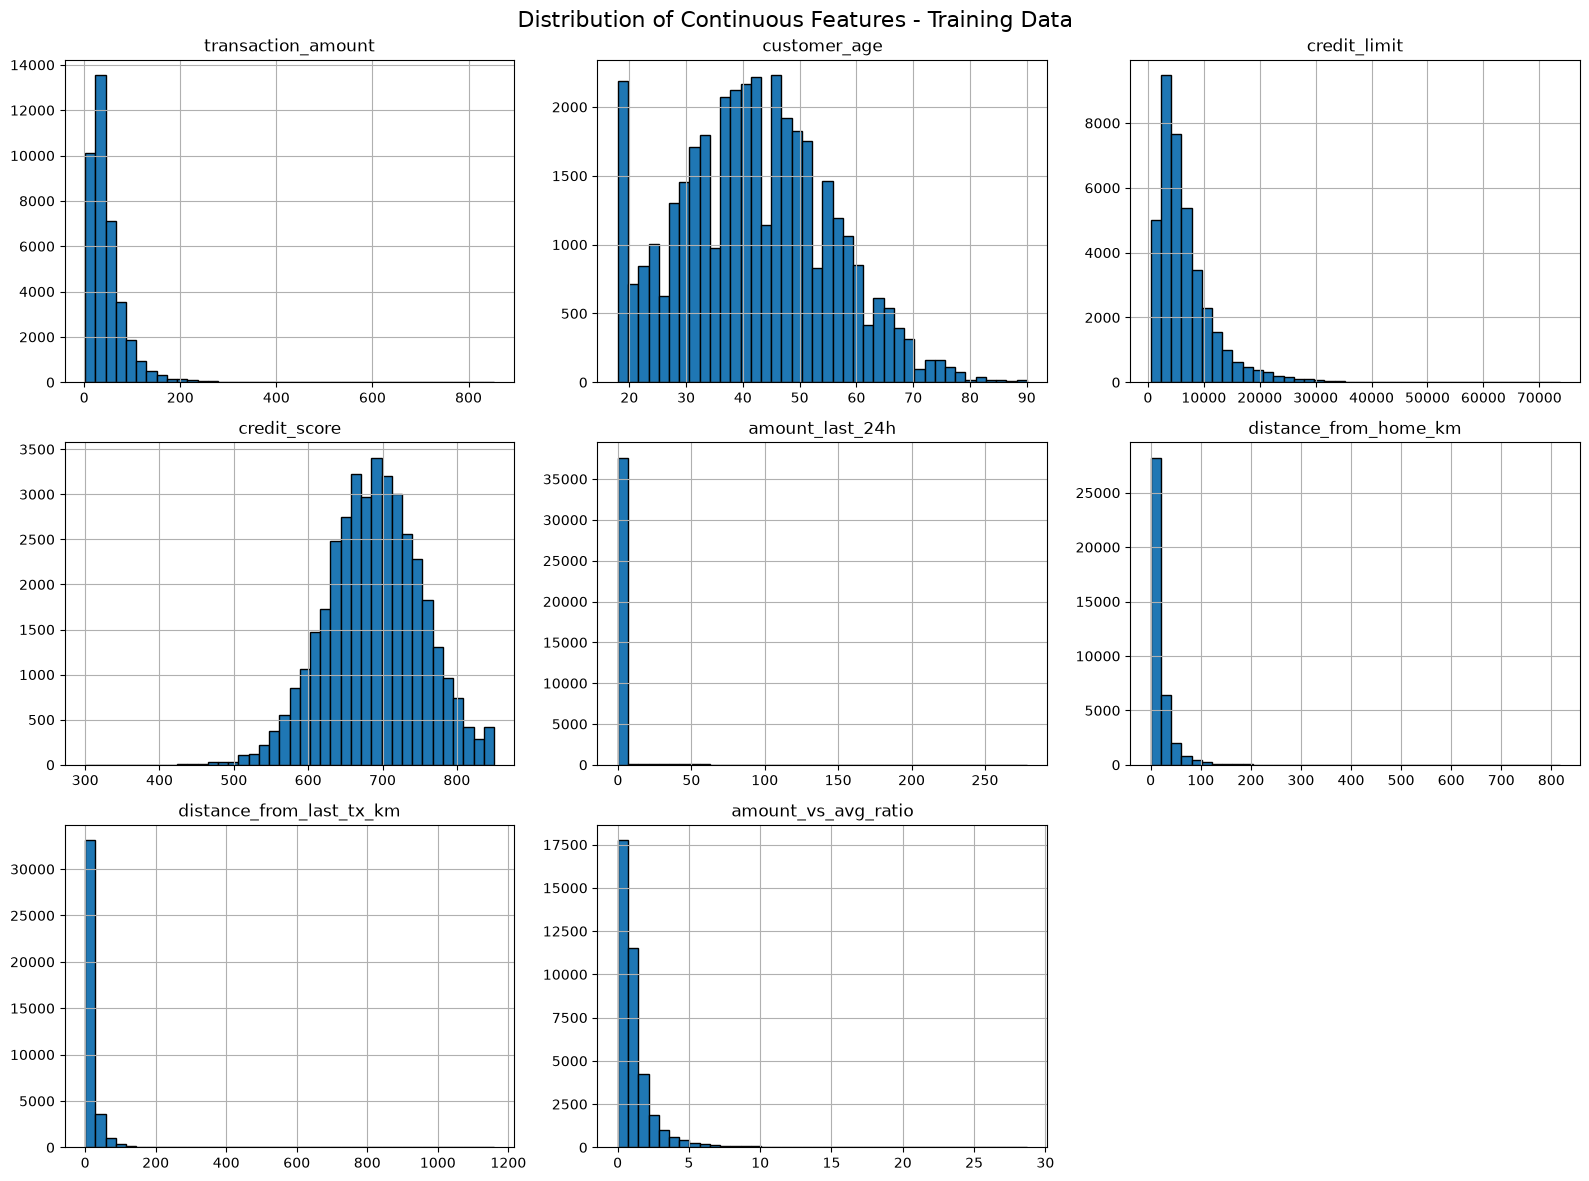

In [129]:
# Visualize distributions of continuous numerical features

import matplotlib.pyplot as plt

X_train_expanded[continuous_features].hist(
    bins=40,
    figsize=(16, 12),
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Continuous Features - Training Data',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [130]:
# Examine zero concentration and extreme values

for col in continuous_features:
    print(f"\n{col}")

    zero_percentage = (
        (X_train_expanded[col] == 0).mean() * 100
    )

    print(f"Zero percentage: {zero_percentage:.2f}%")

    print(
        X_train_expanded[col]
        .quantile([0.50, 0.90, 0.95, 0.99, 1.00])
        .round(2)
    )


transaction_amount
Zero percentage: 0.00%
0.50     36.21
0.90     89.94
0.95    115.08
0.99    190.78
1.00    853.06
Name: transaction_amount, dtype: float64

customer_age
Zero percentage: 0.00%
0.50    42.0
0.90    60.0
0.95    65.0
0.99    74.0
1.00    90.0
Name: customer_age, dtype: float64

credit_limit
Zero percentage: 0.00%
0.50     5244.16
0.90    13004.84
0.95    17207.08
0.99    27689.40
1.00    73621.86
Name: credit_limit, dtype: float64

credit_score
Zero percentage: 0.00%
0.50    689.00
0.90    771.00
0.95    793.25
0.99    839.00
1.00    850.00
Name: credit_score, dtype: float64

amount_last_24h
Zero percentage: 97.79%
0.50      0.00
0.90      0.00
0.95      0.00
0.99     38.84
1.00    278.49
Name: amount_last_24h, dtype: float64

distance_from_home_km
Zero percentage: 0.00%
0.50     10.69
0.90     41.06
0.95     59.71
0.99    117.10
1.00    816.41
Name: distance_from_home_km, dtype: float64

distance_from_last_tx_km
Zero percentage: 0.00%
0.50       8.84
0.90      36.44


In [131]:
# Investigate non-zero amount_last_24h observations

nonzero_amount_24h = X_train_expanded.loc[
    X_train_expanded['amount_last_24h'] > 0,
    'amount_last_24h'
]

print("Non-zero observations:", len(nonzero_amount_24h))

print(
    "Percentage of training data:",
    round(len(nonzero_amount_24h) / len(X_train_expanded) * 100, 2),
    "%"
)

print("\nNon-zero value statistics:")
display(nonzero_amount_24h.describe().round(2))

print("\nNon-zero value percentiles:")
display(
    nonzero_amount_24h
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
    .round(2)
)

Non-zero observations: 852
Percentage of training data: 2.21 %

Non-zero value statistics:


count    852.00
mean      48.15
std       38.97
min        3.07
25%       22.60
50%       35.83
75%       61.40
max      278.49
Name: amount_last_24h, dtype: float64


Non-zero value percentiles:


0.25     22.60
0.50     35.83
0.75     61.40
0.90     96.19
0.95    117.79
0.99    214.62
1.00    278.49
Name: amount_last_24h, dtype: float64

In [132]:
# Calculate skewness of count features

count_skewness = (
    X_train_expanded[count_features]
    .skew()
    .sort_values(ascending=False)
)

display(
    count_skewness
    .to_frame('Skewness')
    .round(3)
)

,Skewness
num_declined_last_30d,9.144
pin_retry_count_24h,6.995
transactions_last_1h,6.667
transactions_last_24h,5.727
merchant_velocity_24h,5.657
failed_auth_attempts_24h,5.208
account_age_days,3.870
transactions_last_7d,2.653
num_cards_held,0.682


In [133]:
# Calculate zero percentages for count features

count_zero_percentage = (
    (X_train_expanded[count_features] == 0)
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(
    count_zero_percentage
    .to_frame('Zero_Percentage')
    .round(2)
)

,Zero_Percentage
num_declined_last_30d,98.78
transactions_last_1h,94.81
pin_retry_count_24h,90.99
transactions_last_24h,90.30
transactions_last_7d,86.38
failed_auth_attempts_24h,84.85
merchant_velocity_24h,80.64
account_age_days,0.00
num_cards_held,0.00


In [134]:
# Inspect value frequencies for count features

for col in count_features:
    print(f"\n{col}")

    display(
        X_train_expanded[col]
        .value_counts()
        .sort_index()
        .head(15)
        .to_frame('Transactions')
    )


account_age_days


,Transactions
account_age_days,
15,3
16,1
18,1
19,2
20,1
21,1
22,5
23,2
24,2



num_cards_held


,Transactions
num_cards_held,
1,6097
2,11451
3,10258
4,6229
5,2928
6,1160
7,283
8,70



transactions_last_1h


,Transactions
transactions_last_1h,
0,36481
1,819
2,497
3,309
4,182
5,100
6,57
7,13
8,18


... (8 outputs left out)


merchant_velocity_24h


,Transactions
merchant_velocity_24h,
0,31027
1,5114
2,874
3,444
4,320
5,239
6,148
7,90
8,78



pin_retry_count_24h


,Transactions
pin_retry_count_24h,
0,35009
1,2586
2,303
3,191
4,154
5,106
6,53
7,34
8,20


In [135]:
# Examine the number of unique categories in each categorical feature

categorical_cardinality = (
    X_train_expanded[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

display(
    categorical_cardinality
    .to_frame('Unique_Categories')
)

,Unique_Categories
merchant_country,12
customer_country,12
merchant_category,10
transaction_day_of_week,7
email_domain,7
browser,6
device_type,5
transaction_channel,5
customer_gender,4


In [136]:
# Examine category frequencies in each categorical feature

for col in categorical_features:
    print(f"\n{col}")

    display(
        X_train_expanded[col]
        .value_counts(dropna=False)
        .to_frame('Transactions')
    )


merchant_category


,Transactions
merchant_category,
retail,6810
grocery,6199
restaurant,5334
fuel,4053
electronics,3234
digital_goods,3189
subscription,3023
health,2676
travel,2455



merchant_country


,Transactions
merchant_country,
US,18629
IN,3616
GB,3422
CA,2472
DE,2366
FR,1741
IE,1487
ES,1189
SG,1014



transaction_day_of_week


,Transactions
transaction_day_of_week,
Thursday,5920
Friday,5857
Saturday,5734
Tuesday,5329
Wednesday,5234
Sunday,5201
Monday,5201


... (8 outputs left out)


browser


,Transactions
browser,
none,19343
Chrome,6392
in_app,5854
Safari,3703
Edge,1829
Firefox,1355



email_domain


,Transactions
email_domain,
gmail.com,11576
outlook.com,7413
yahoo.com,6936
icloud.com,3973
other,3926
business.com,3087
proton.me,1565


In [137]:
# Check for categories not observed in training data

for col in categorical_features:

    train_categories = set(X_train_expanded[col].unique())
    validation_categories = set(X_validation_expanded[col].unique())
    test_categories = set(X_test_expanded[col].unique())

    unseen_validation = validation_categories - train_categories
    unseen_test = test_categories - train_categories

    print(f"\n{col}")
    print("Training categories:", len(train_categories))
    print("Unseen in validation:", unseen_validation)
    print("Unseen in testing:", unseen_test)


merchant_category
Training categories: 10
Unseen in validation: set()
Unseen in testing: set()

merchant_country
Training categories: 12
Unseen in validation: set()
Unseen in testing: set()

transaction_day_of_week
Training categories: 7
Unseen in validation: set()
Unseen in testing: set()

customer_gender
Training categories: 4
Unseen in validation: set()
Unseen in testing: set()

customer_country
Training categories: 12
Unseen in validation: set()
Unseen in testing: set()

transaction_channel
Training categories: 5
Unseen in validation: set()
Unseen in testing: set()

device_type
Training categories: 5
Unseen in validation: set()
Unseen in testing: set()

browser
Training categories: 6
Unseen in validation: set()
Unseen in testing: set()

email_domain
Training categories: 7
Unseen in validation: set()
Unseen in testing: set()


In [138]:
# Check installed machine-learning library versions

import sklearn
import imblearn

print("Scikit-learn version:", sklearn.__version__)
print("Imbalanced-learn version:", imblearn.__version__)

Scikit-learn version: 1.9.0
Imbalanced-learn version: 0.14.2


In [139]:
# Validate numerical feature group assignments

print("Binary features:", len(binary_features))
print("Count features:", len(count_features))
print("Temporal numerical features:", len(temporal_features))
print("Continuous features:", len(continuous_features))

all_numerical_groups = (
    binary_features
    + count_features
    + temporal_features
    + continuous_features
)

print("\nTotal assigned:", len(all_numerical_groups))
print("Unique assigned:", len(set(all_numerical_groups)))
print("Actual numerical features:", len(numerical_features))

print(
    "\nAll numerical features accounted for:",
    set(all_numerical_groups) == set(numerical_features)
)

Binary features: 9
Count features: 9
Temporal numerical features: 3
Continuous features: 8

Total assigned: 29
Unique assigned: 29
Actual numerical features: 29

All numerical features accounted for: True


In [140]:
# Validate numerical and categorical feature assignments

all_expanded_groups = all_numerical_groups + categorical_features

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nTotal assigned:", len(all_expanded_groups))
print("Unique assigned:", len(set(all_expanded_groups)))
print("Actual expanded features:", X_train_expanded.shape[1])

print(
    "\nAll expanded features accounted for:",
    set(all_expanded_groups) == set(X_train_expanded.columns)
)

Numerical features: 29
Categorical features: 9

Total assigned: 38
Unique assigned: 38
Actual expanded features: 38

All expanded features accounted for: True


In [141]:
# Inspect data types of verified baseline features

display(
    X_train_verified.dtypes
    .to_frame('Data_Type')
)

,Data_Type
month,int64
week_of_year,int64
transaction_hour,int64
transaction_day_of_week,str


In [142]:
# Separate verified baseline features by data type

baseline_numerical_features = [
    col for col in X_train_verified.columns
    if pd.api.types.is_numeric_dtype(X_train_verified[col])
]

baseline_categorical_features = [
    col for col in X_train_verified.columns
    if not pd.api.types.is_numeric_dtype(X_train_verified[col])
]

print("Baseline numerical features:", baseline_numerical_features)
print("Baseline categorical features:", baseline_categorical_features)

print("\nTotal baseline features:",
      len(baseline_numerical_features) + len(baseline_categorical_features))

Baseline numerical features: ['month', 'week_of_year', 'transaction_hour']
Baseline categorical features: ['transaction_day_of_week']

Total baseline features: 4


In [143]:
# Validate baseline feature assignments

all_baseline_groups = (
    baseline_numerical_features
    + baseline_categorical_features
)

print("Total assigned:", len(all_baseline_groups))
print("Unique assigned:", len(set(all_baseline_groups)))
print("Actual baseline features:", X_train_verified.shape[1])

print(
    "\nAll baseline features accounted for:",
    set(all_baseline_groups) == set(X_train_verified.columns)
)

Total assigned: 4
Unique assigned: 4
Actual baseline features: 4

All baseline features accounted for: True


In [144]:
# Review numerical feature groups
# Display numerical feature groups for preprocessing decisions

print("Binary features:")
print(binary_features)

print("\nCount features:")
print(count_features)

print("\nTemporal numerical features:")
print(temporal_features)

print("\nContinuous features:")
print(continuous_features)

Binary features:
['card_present', 'international_transaction', 'high_risk_country', 'used_chip', 'used_pin', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'pos_entry_fallback']

Count features:
['account_age_days', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'num_declined_last_30d', 'failed_auth_attempts_24h', 'merchant_velocity_24h', 'pin_retry_count_24h']

Temporal numerical features:
['month', 'week_of_year', 'transaction_hour']

Continuous features:
['transaction_amount', 'customer_age', 'credit_limit', 'credit_score', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio']


In [145]:
# Examine the distribution of binary numerical features

binary_distribution = pd.DataFrame({
    'Zero_Count': (X_train_expanded[binary_features] == 0).sum(),
    'One_Count': (X_train_expanded[binary_features] == 1).sum(),
    'One_Percentage': (
        X_train_expanded[binary_features].mean() * 100
    ).round(2)
})

display(binary_distribution)

,Zero_Count,One_Count,One_Percentage
card_present,19709,18767,48.78
international_transaction,34055,4421,11.49
high_risk_country,35987,2489,6.47
used_chip,24045,14431,37.51
used_pin,26446,12030,31.27
device_change_7d,35375,3101,8.06
billing_shipping_mismatch,36128,2348,6.10
account_profile_change_7d,36546,1930,5.02
pos_entry_fallback,31297,7179,18.66


In [146]:
# Examine count feature distributions

count_distribution = X_train_expanded[count_features].describe().T

display(
    count_distribution[
        ['min', '25%', '50%', '75%', 'max', 'mean', 'std']
    ].round(2)
)

,min,25%,50%,75%,max,mean,std
account_age_days,15.0,249.0,469.0,928.0,19953.0,772.60,894.17
num_cards_held,1.0,2.0,3.0,4.0,8.0,2.83,1.34
transactions_last_1h,0.0,0.0,0.0,0.0,8.0,0.12,0.61
transactions_last_24h,0.0,0.0,0.0,0.0,20.0,0.40,1.68
transactions_last_7d,0.0,0.0,0.0,0.0,4.0,0.15,0.39
num_declined_last_30d,0.0,0.0,0.0,0.0,2.0,0.01,0.11
failed_auth_attempts_24h,0.0,0.0,0.0,0.0,9.0,0.23,0.70
merchant_velocity_24h,0.0,0.0,0.0,0.0,15.0,0.37,1.16
pin_retry_count_24h,0.0,0.0,0.0,0.0,9.0,0.15,0.65


In [147]:
# Reclassify account_age_days as a continuous duration feature

count_features.remove('account_age_days')
continuous_features.append('account_age_days')

print("Count features:", len(count_features))
print("Continuous/duration features:", len(continuous_features))

print("\nUpdated count features:")
print(count_features)

print("\nUpdated continuous features:")
print(continuous_features)

Count features: 8
Continuous/duration features: 9

Updated count features:
['num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'num_declined_last_30d', 'failed_auth_attempts_24h', 'merchant_velocity_24h', 'pin_retry_count_24h']

Updated continuous features:
['transaction_amount', 'customer_age', 'credit_limit', 'credit_score', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'amount_vs_avg_ratio', 'account_age_days']


In [148]:
# Examine skewness of the revised count features

count_skewness = (
    X_train_expanded[count_features]
    .skew()
    .sort_values(ascending=False)
)

display(
    count_skewness.to_frame('Skewness').round(3)
)

,Skewness
num_declined_last_30d,9.144
pin_retry_count_24h,6.995
transactions_last_1h,6.667
transactions_last_24h,5.727
merchant_velocity_24h,5.657
failed_auth_attempts_24h,5.208
transactions_last_7d,2.653
num_cards_held,0.682


In [149]:
# Examine temporal numerical feature distributions

temporal_distribution = (
    X_train_expanded[temporal_features]
    .describe()
    .T
)

display(
    temporal_distribution[
        ['min', '25%', '50%', '75%', 'max', 'mean', 'std']
    ].round(2)
)

,min,25%,50%,75%,max,mean,std
month,1.0,1.0,1.0,2.0,2.0,1.48,0.50
week_of_year,1.0,3.0,5.0,7.0,9.0,5.14,2.45
transaction_hour,0.0,5.0,11.0,17.0,23.0,11.46,6.92


In [150]:
# Compare temporal feature ranges across all data partitions

for split_name, split_data in {
    'Training': X_train_expanded,
    'Validation': X_validation_expanded,
    'Testing': X_test_expanded
}.items():

    print(f"\n{split_name}")

    display(
        split_data[temporal_features]
        .agg(['min', 'max', 'nunique'])
        .T
    )


Training


,min,max,nunique
month,1,2,2
week_of_year,1,9,9
transaction_hour,0,23,24



Validation


,min,max,nunique
month,3,3,1
week_of_year,9,14,6
transaction_hour,0,23,24



Testing


,min,max,nunique
month,4,6,3
week_of_year,14,27,14
transaction_hour,0,23,24


In [151]:
# Examine continuous and duration feature distributions

continuous_distribution = (
    X_train_expanded[continuous_features]
    .describe()
    .T
)

display(
    continuous_distribution[
        ['min', '25%', '50%', '75%', 'max', 'mean', 'std']
    ].round(2)
)

,min,25%,50%,75%,max,mean,std
transaction_amount,1.99,22.65,36.21,58.35,853.06,46.72,38.00
customer_age,18.00,32.00,42.00,51.00,90.00,41.91,13.41
credit_limit,500.00,3224.16,5244.16,8431.06,73621.86,6731.85,5426.23
credit_score,300.00,646.00,689.00,732.00,850.00,688.75,64.09
amount_last_24h,0.00,0.00,0.00,0.00,278.49,1.07,9.15
distance_from_home_km,0.11,5.37,10.69,21.67,816.41,18.39,25.23
distance_from_last_tx_km,0.07,4.21,8.84,18.45,1159.35,16.51,26.64
amount_vs_avg_ratio,0.02,0.47,0.80,1.41,28.70,1.23,1.43
account_age_days,15.00,249.00,469.00,928.00,19953.00,772.60,894.17


In [152]:
# Examine skewness of continuous and duration features

continuous_skewness = (
    X_train_expanded[continuous_features]
    .skew()
    .sort_values(ascending=False)
)

display(
    continuous_skewness.to_frame('Skewness').round(3)
)

,Skewness
amount_last_24h,13.202
distance_from_last_tx_km,8.461
distance_from_home_km,6.294
amount_vs_avg_ratio,4.329
account_age_days,3.870
transaction_amount,3.255
credit_limit,2.582
customer_age,0.211
credit_score,-0.116


In [153]:
# Verify whether continuous features are suitable for log1p candidates

continuous_minimums = X_train_expanded[continuous_features].min()

transformation_check = pd.DataFrame({
    'Minimum_Value': continuous_minimums,
    'Contains_Negative': continuous_minimums < 0,
    'Contains_Zero': (X_train_expanded[continuous_features] == 0).any()
})

display(transformation_check)

,Minimum_Value,Contains_Negative,Contains_Zero
transaction_amount,1.9900,False,False
customer_age,18.0000,False,False
credit_limit,500.0000,False,False
credit_score,300.0000,False,False
amount_last_24h,0.0000,False,True
distance_from_home_km,0.1100,False,False
distance_from_last_tx_km,0.0700,False,False
amount_vs_avg_ratio,0.0222,False,False
account_age_days,15.0000,False,False


In [154]:
# Compare skewness before and after log1p transformation

skewness_comparison = pd.DataFrame({
    'Original_Skewness': X_train_expanded[continuous_features].skew(),
    'Log1p_Skewness': np.log1p(
        X_train_expanded[continuous_features]
    ).skew()
})

skewness_comparison['Skewness_Change'] = (
    skewness_comparison['Original_Skewness']
    - skewness_comparison['Log1p_Skewness']
)

display(skewness_comparison.round(3))

,Original_Skewness,Log1p_Skewness,Skewness_Change
transaction_amount,3.255,0.110,3.145
customer_age,0.211,-0.530,0.741
credit_limit,2.582,-0.021,2.603
credit_score,-0.116,-0.439,0.323
amount_last_24h,13.202,6.847,6.355
distance_from_home_km,6.294,0.296,5.998
distance_from_last_tx_km,8.461,0.405,8.057
amount_vs_avg_ratio,4.329,1.425,2.904
account_age_days,3.870,0.134,3.736


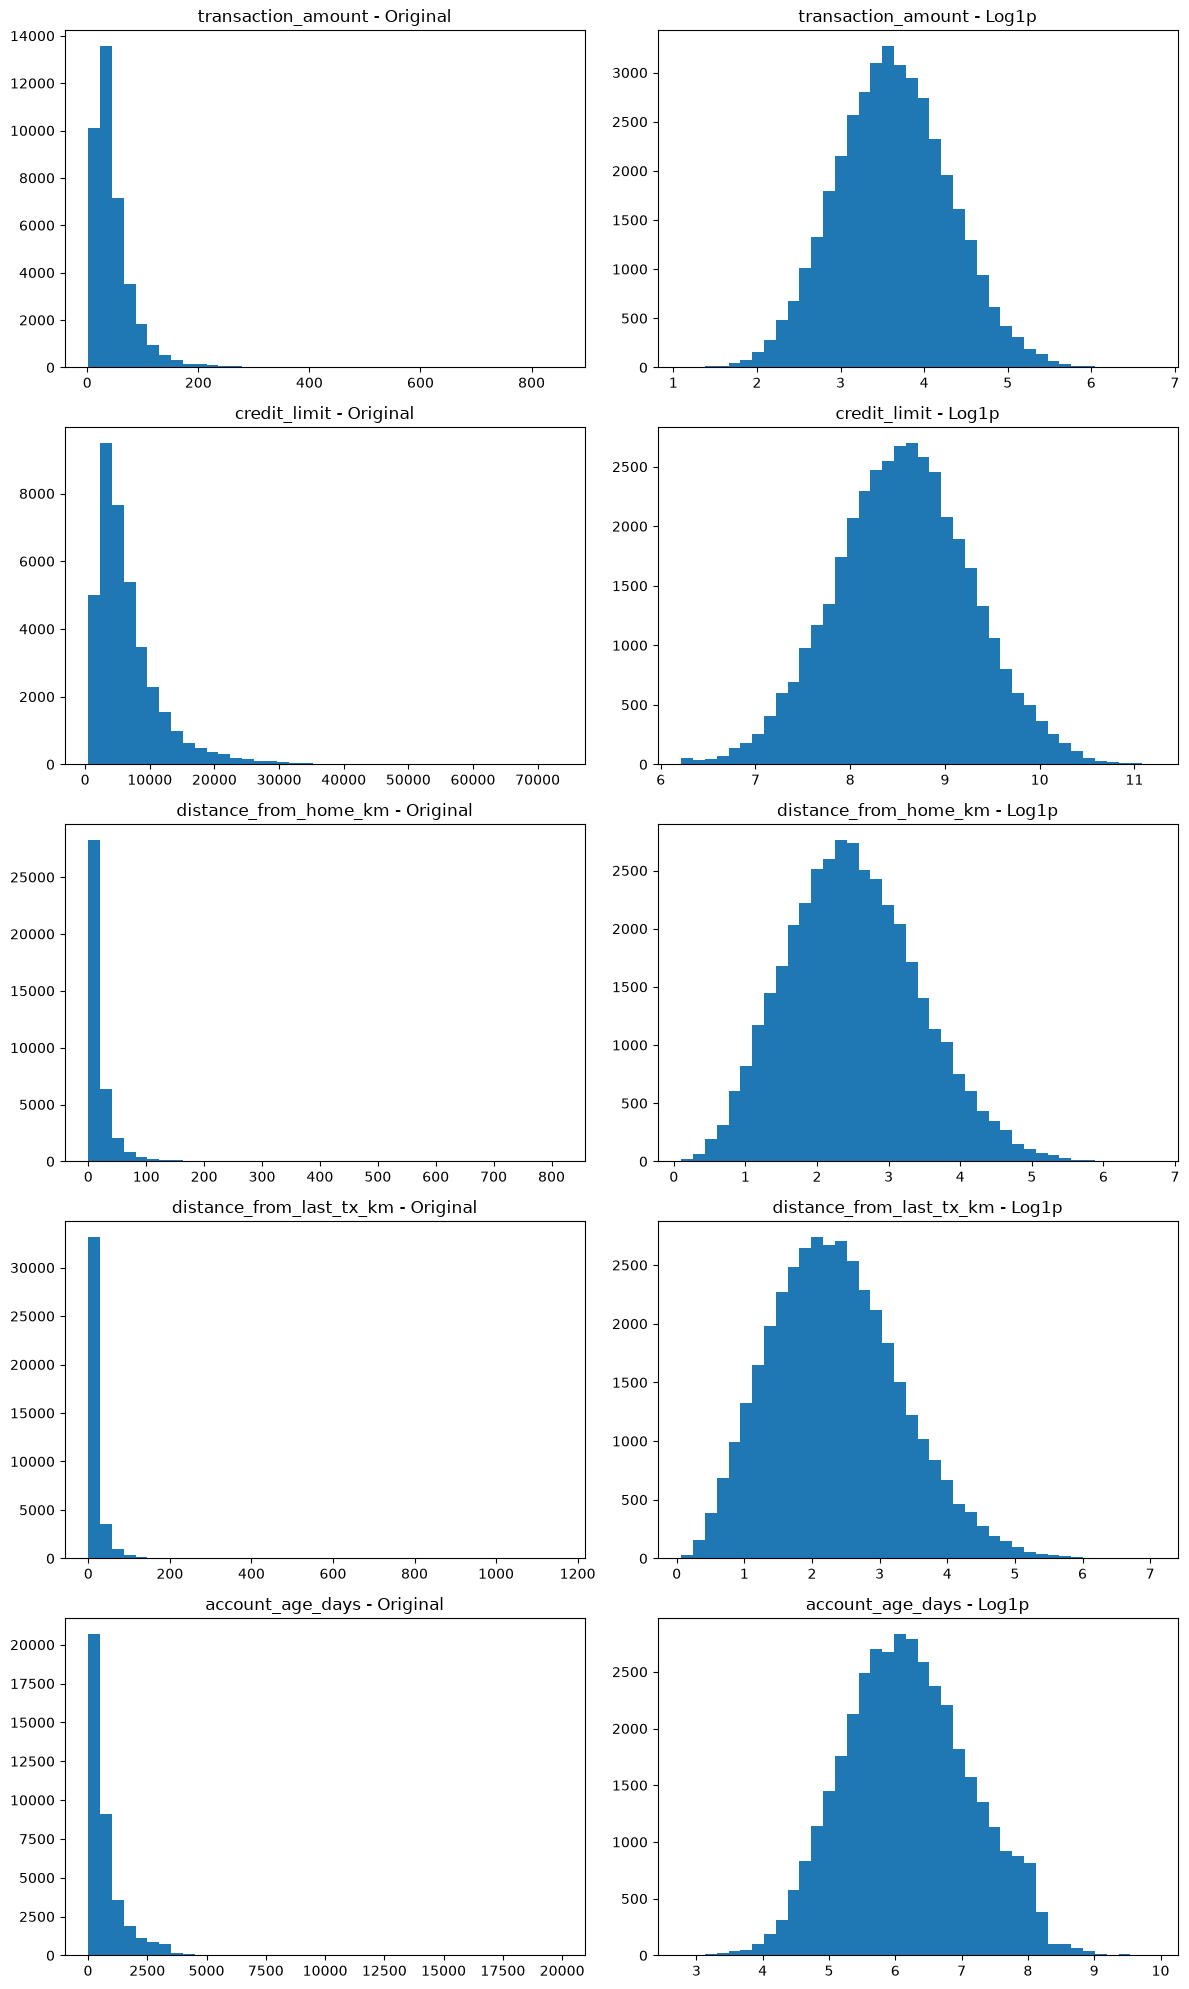

In [155]:
# Compare original and log1p-transformed distributions

import matplotlib.pyplot as plt

log_candidates = [
    'transaction_amount',
    'credit_limit',
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'account_age_days'
]

fig, axes = plt.subplots(
    len(log_candidates), 2,
    figsize=(12, 20)
)

for i, col in enumerate(log_candidates):

    axes[i, 0].hist(
        X_train_expanded[col],
        bins=40
    )
    axes[i, 0].set_title(f'{col} - Original')

    axes[i, 1].hist(
        np.log1p(X_train_expanded[col]),
        bins=40
    )
    axes[i, 1].set_title(f'{col} - Log1p')

plt.tight_layout()
plt.show()

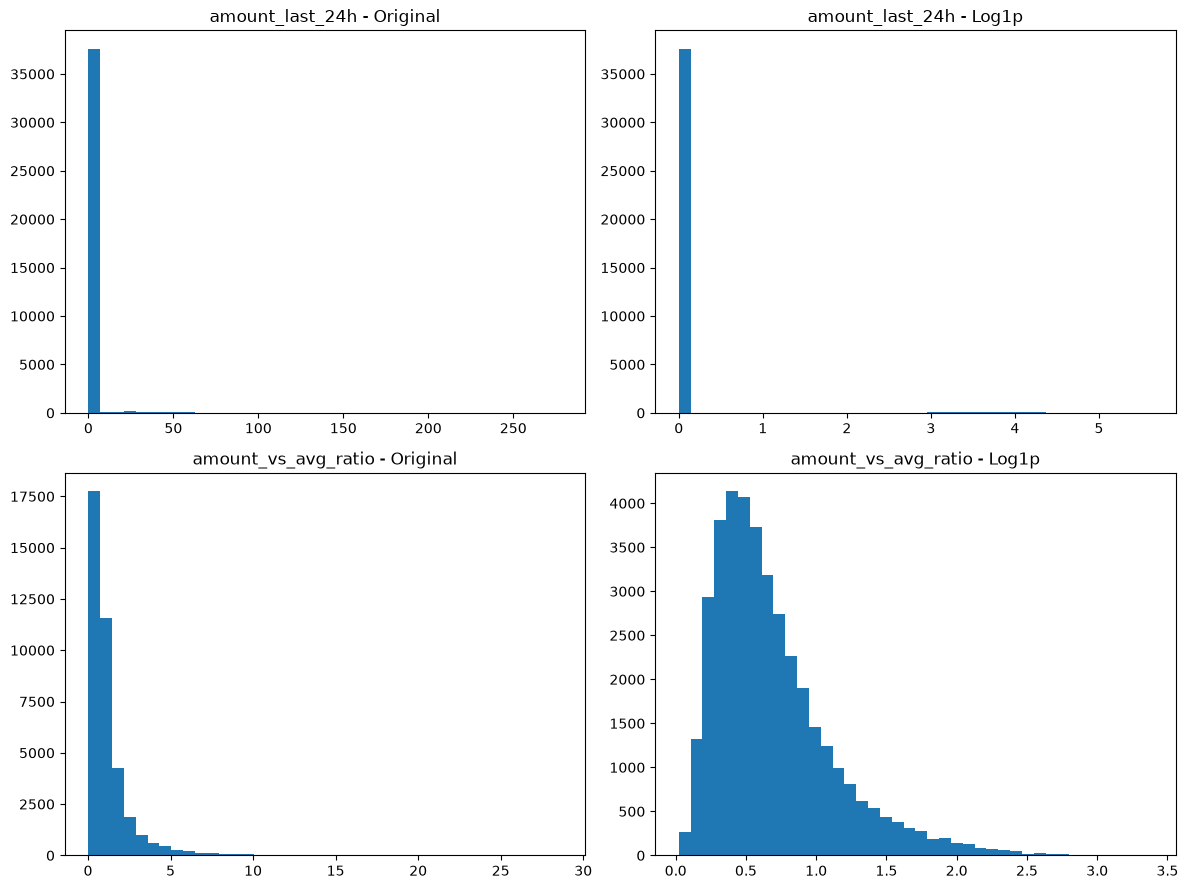

In [156]:
# Examine zero-heavy and moderately skewed features

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# amount_last_24h: original distribution
axes[0, 0].hist(
    X_train_expanded['amount_last_24h'],
    bins=40
)
axes[0, 0].set_title('amount_last_24h - Original')

# amount_last_24h: log1p distribution
axes[0, 1].hist(
    np.log1p(X_train_expanded['amount_last_24h']),
    bins=40
)
axes[0, 1].set_title('amount_last_24h - Log1p')

# amount_vs_avg_ratio: original distribution
axes[1, 0].hist(
    X_train_expanded['amount_vs_avg_ratio'],
    bins=40
)
axes[1, 0].set_title('amount_vs_avg_ratio - Original')

# amount_vs_avg_ratio: log1p distribution
axes[1, 1].hist(
    np.log1p(X_train_expanded['amount_vs_avg_ratio']),
    bins=40
)
axes[1, 1].set_title('amount_vs_avg_ratio - Log1p')

plt.tight_layout()
plt.show()

In [157]:
# Investigate the non-zero values separately

positive_amounts = X_train_expanded.loc[
    X_train_expanded['amount_last_24h'] > 0,
    'amount_last_24h'
]

print("Total training observations:", len(X_train_expanded))
print("Zero observations:", (X_train_expanded['amount_last_24h'] == 0).sum())
print("Positive observations:", len(positive_amounts))

print("\nPositive-value statistics:")
display(positive_amounts.describe().to_frame())

print("\nPositive-value skewness:")
print(round(positive_amounts.skew(), 3))

print("\nPositive-value log1p skewness:")
print(round(np.log1p(positive_amounts).skew(), 3))

Total training observations: 38476
Zero observations: 37624
Positive observations: 852

Positive-value statistics:


,amount_last_24h
count,852.000000
mean,48.145646
std,38.970117
min,3.070000
25%,22.595000
50%,35.825000
75%,61.402500
max,278.490000



Positive-value skewness:
2.351

Positive-value log1p skewness:
0.186


In [158]:
# Create an experimental copy for transformation analysis

X_train_transform_check = X_train_expanded.copy()

# Apply log1p to selected continuous features
log_features = [
    'transaction_amount',
    'credit_limit',
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'account_age_days',
    'amount_vs_avg_ratio'
]

for col in log_features:
    X_train_transform_check[f'{col}_log'] = np.log1p(
        X_train_transform_check[col]
    )

# Experimental two-part representation for amount_last_24h
X_train_transform_check['amount_last_24h_is_positive'] = (
    X_train_transform_check['amount_last_24h'] > 0
).astype(int)

X_train_transform_check['amount_last_24h_log'] = np.log1p(
    X_train_transform_check['amount_last_24h']
)

print("Original training shape:", X_train_expanded.shape)
print("Experimental training shape:", X_train_transform_check.shape)

display(
    X_train_transform_check[
        [
            'amount_last_24h',
            'amount_last_24h_is_positive',
            'amount_last_24h_log'
        ]
    ].head(10)
)

Original training shape: (38476, 38)
Experimental training shape: (38476, 46)


,amount_last_24h,amount_last_24h_is_positive,amount_last_24h_log
0,0.0,0,0.0
1,0.0,0,0.0
2,0.0,0,0.0
3,0.0,0,0.0
4,0.0,0,0.0
5,0.0,0,0.0
6,0.0,0,0.0
7,0.0,0,0.0
8,0.0,0,0.0
9,0.0,0,0.0


In [159]:
# Inspect rows where amount_last_24h is positive

positive_sample = X_train_transform_check.loc[
    X_train_transform_check['amount_last_24h'] > 0,
    [
        'amount_last_24h',
        'amount_last_24h_is_positive',
        'amount_last_24h_log'
    ]
]

print("Positive observations:", len(positive_sample))

display(positive_sample.head(10))

# Validate the transformation
assert (
    positive_sample['amount_last_24h_is_positive'] == 1
).all()

assert np.allclose(
    positive_sample['amount_last_24h_log'],
    np.log1p(positive_sample['amount_last_24h'])
)

print("\nPositive-value transformation verified successfully.")

Positive observations: 852


,amount_last_24h,amount_last_24h_is_positive,amount_last_24h_log
167,21.45,1,3.111291
279,17.80,1,2.933857
483,70.31,1,4.267037
618,43.36,1,3.792338
773,31.69,1,3.487069
846,32.19,1,3.502249
887,98.54,1,4.600560
1101,47.50,1,3.881564
1107,24.58,1,3.241811
1125,29.07,1,3.403528



Positive-value transformation verified successfully.


In [160]:
# # Consolidate preliminary numerical preprocessing decisions
# Consolidate preliminary numerical preprocessing decisions

preprocessing_decisions = {
    'Feature_Group': (
        ['Binary'] * 9 +
        ['Count'] * 8 +
        ['Temporal'] * 3 +
        ['Continuous'] * 9
    ),
    'Feature': (
        binary_features +
        count_features +
        temporal_features +
        continuous_features
    ),
    'Preliminary_Treatment': (
        ['Preserve original 0/1 values'] * 9 +
        ['Investigate scaling and possible log1p'] * 8 +
        [
            'Cyclical encoding candidate',
            'Preserve numerical initially',
            'Preserve numerical initially'
        ] +
        [
            'log1p candidate',
            'Preserve original',
            'log1p candidate',
            'Preserve original',
            'Two-part representation candidate',
            'log1p candidate',
            'log1p candidate',
            'log1p candidate',
            'log1p candidate'
        ]
    )
}

preprocessing_decision_df = pd.DataFrame(preprocessing_decisions)

display(preprocessing_decision_df)

,Feature_Group,Feature,Preliminary_Treatment
0,Binary,card_present,Preserve original 0/1 values
1,Binary,international_transaction,Preserve original 0/1 values
2,Binary,high_risk_country,Preserve original 0/1 values
3,Binary,used_chip,Preserve original 0/1 values
4,Binary,used_pin,Preserve original 0/1 values
5,Binary,device_change_7d,Preserve original 0/1 values
6,Binary,billing_shipping_mismatch,Preserve original 0/1 values
7,Binary,account_profile_change_7d,Preserve original 0/1 values
8,Binary,pos_entry_fallback,Preserve original 0/1 values
9,Count,num_cards_held,Investigate scaling and possible log1p


In [161]:
# Correct preliminary temporal preprocessing decisions

temporal_treatments = {
    'month': 'Preserve numerical initially',
    'week_of_year': 'Preserve numerical initially',
    'transaction_hour': 'Cyclical encoding candidate'
}

preprocessing_decision_df['Preliminary_Treatment'] = (
    preprocessing_decision_df['Feature']
    .map(temporal_treatments)
    .fillna(preprocessing_decision_df['Preliminary_Treatment'])
)

display(
    preprocessing_decision_df[
        preprocessing_decision_df['Feature_Group'] == 'Temporal'
    ]
)

,Feature_Group,Feature,Preliminary_Treatment
17,Temporal,month,Preserve numerical initially
18,Temporal,week_of_year,Preserve numerical initially
19,Temporal,transaction_hour,Cyclical encoding candidate


In [162]:
# Compare original and log1p-transformed count-feature skewness

count_skewness_comparison = pd.DataFrame({
    'Original_Skewness': X_train_expanded[count_features].skew(),
    'Log1p_Skewness': np.log1p(
        X_train_expanded[count_features]
    ).skew()
})

count_skewness_comparison['Skewness_Change'] = (
    count_skewness_comparison['Original_Skewness']
    - count_skewness_comparison['Log1p_Skewness']
)

display(count_skewness_comparison.round(3))

,Original_Skewness,Log1p_Skewness,Skewness_Change
num_cards_held,0.682,-0.089,0.771
transactions_last_1h,6.667,4.937,1.730
transactions_last_24h,5.727,3.707,2.020
transactions_last_7d,2.653,2.285,0.368
num_declined_last_30d,9.144,8.952,0.192
failed_auth_attempts_24h,5.208,2.784,2.424
merchant_velocity_24h,5.657,2.640,3.016
pin_retry_count_24h,6.995,4.060,2.935


In [163]:
# Examine zero concentration in count features

count_zero_summary = pd.DataFrame({
    'Zero_Count': (X_train_expanded[count_features] == 0).sum(),
    'Zero_Percentage': (
        X_train_expanded[count_features] == 0
    ).mean() * 100,
    'Positive_Count': (X_train_expanded[count_features] > 0).sum()
})

display(count_zero_summary.round(2))

,Zero_Count,Zero_Percentage,Positive_Count
num_cards_held,0,0.00,38476
transactions_last_1h,36481,94.81,1995
transactions_last_24h,34745,90.30,3731
transactions_last_7d,33235,86.38,5241
num_declined_last_30d,38005,98.78,471
failed_auth_attempts_24h,32645,84.85,5831
merchant_velocity_24h,31027,80.64,7449
pin_retry_count_24h,35009,90.99,3467


In [164]:
# Finalize preliminary count-feature treatments

count_treatments = {
    'num_cards_held': 'Preserve original initially',
    'transactions_last_1h': 'log1p candidate',
    'transactions_last_24h': 'log1p candidate',
    'transactions_last_7d': 'Preserve original initially',
    'num_declined_last_30d': 'Preserve original initially',
    'failed_auth_attempts_24h': 'log1p candidate',
    'merchant_velocity_24h': 'log1p candidate',
    'pin_retry_count_24h': 'log1p candidate'
}

preprocessing_decision_df['Preliminary_Treatment'] = (
    preprocessing_decision_df['Feature']
    .map(count_treatments)
    .fillna(preprocessing_decision_df['Preliminary_Treatment'])
)

display(
    preprocessing_decision_df[
        preprocessing_decision_df['Feature_Group'] == 'Count'
    ]
)

,Feature_Group,Feature,Preliminary_Treatment
9,Count,num_cards_held,Preserve original initially
10,Count,transactions_last_1h,log1p candidate
11,Count,transactions_last_24h,log1p candidate
12,Count,transactions_last_7d,Preserve original initially
13,Count,num_declined_last_30d,Preserve original initially
14,Count,failed_auth_attempts_24h,log1p candidate
15,Count,merchant_velocity_24h,log1p candidate
16,Count,pin_retry_count_24h,log1p candidate


In [165]:
# Review categorical features before encoding

categorical_review = pd.DataFrame({
    'Data_Type': X_train_expanded[categorical_features].dtypes.astype(str),
    'Unique_Values': X_train_expanded[categorical_features].nunique(),
    'Missing_Values': X_train_expanded[categorical_features].isna().sum()
})

display(categorical_review)

,Data_Type,Unique_Values,Missing_Values
merchant_category,str,10,0
merchant_country,str,12,0
transaction_day_of_week,str,7,0
customer_gender,str,4,0
customer_country,str,12,0
transaction_channel,str,5,0
device_type,str,5,0
browser,str,6,0
email_domain,str,7,0


In [166]:
# Estimate the number of columns after one-hot encoding

category_counts = X_train_expanded[
    categorical_features
].nunique()

print("Categorical features:", len(categorical_features))
print("\nUnique categories per feature:")
display(category_counts.to_frame('Unique_Categories'))

print(
    "\nExpected one-hot encoded columns:",
    category_counts.sum()
)

Categorical features: 9

Unique categories per feature:


,Unique_Categories
merchant_category,10
merchant_country,12
transaction_day_of_week,7
customer_gender,4
customer_country,12
transaction_channel,5
device_type,5
browser,6
email_domain,7



Expected one-hot encoded columns: 68


In [167]:
# Define preliminary numerical transformation groups

binary_passthrough_features = binary_features.copy()

count_log_features = [
    'transactions_last_1h',
    'transactions_last_24h',
    'failed_auth_attempts_24h',
    'merchant_velocity_24h',
    'pin_retry_count_24h'
]

count_original_features = [
    'num_cards_held',
    'transactions_last_7d',
    'num_declined_last_30d'
]

continuous_log_features = [
    'transaction_amount',
    'credit_limit',
    'distance_from_home_km',
    'distance_from_last_tx_km',
    'amount_vs_avg_ratio',
    'account_age_days'
]

continuous_original_features = [
    'customer_age',
    'credit_score'
]

special_amount_features = ['amount_last_24h']

cyclical_features = ['transaction_hour']

temporal_original_features = [
    'month',
    'week_of_year'
]

print("Feature groups defined successfully.")

Feature groups defined successfully.


In [168]:
# Validate numerical feature grouping

all_numerical_groups = (
    binary_passthrough_features +
    count_log_features +
    count_original_features +
    continuous_log_features +
    continuous_original_features +
    special_amount_features +
    cyclical_features +
    temporal_original_features
)

print("Expected numerical features:", len(numerical_features))
print("Assigned features:", len(all_numerical_groups))
print("Unique assigned features:", len(set(all_numerical_groups)))

print(
    "\nMissing features:",
    set(numerical_features) - set(all_numerical_groups)
)

print(
    "\nDuplicate assignments:",
    [
        feature for feature in set(all_numerical_groups)
        if all_numerical_groups.count(feature) > 1
    ]
)

assert set(all_numerical_groups) == set(numerical_features)
assert len(all_numerical_groups) == len(set(all_numerical_groups))

print("\nAll numerical features are accounted for exactly once.")

Expected numerical features: 29
Assigned features: 29
Unique assigned features: 29

Missing features: set()

Duplicate assignments: []

All numerical features are accounted for exactly once.


In [169]:
# Validate numerical and categorical feature coverage

all_preprocessing_features = (
    all_numerical_groups +
    categorical_features
)

print("Expected expanded features:", X_train_expanded.shape[1])
print("Assigned features:", len(all_preprocessing_features))
print("Unique assigned features:", len(set(all_preprocessing_features)))

print(
    "\nMissing features:",
    set(X_train_expanded.columns) - set(all_preprocessing_features)
)

print(
    "\nUnexpected features:",
    set(all_preprocessing_features) - set(X_train_expanded.columns)
)

assert set(all_preprocessing_features) == set(X_train_expanded.columns)
assert len(all_preprocessing_features) == len(set(all_preprocessing_features))

print("\nAll expanded features are accounted for exactly once.")

Expected expanded features: 38
Assigned features: 38
Unique assigned features: 38

Missing features: set()

Unexpected features: set()

All expanded features are accounted for exactly once.


## 9. Expanded Preprocessing Pipeline Construction and Validation

In [170]:
from sklearn.preprocessing import OneHotEncoder

categorical_encoder = OneHotEncoder(
    handle_unknown='ignore'
)

print("Categorical encoder initialized successfully.")

Categorical encoder initialized successfully.


In [171]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(
    steps=[
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

print("Categorical preprocessing pipeline created successfully.")

Categorical preprocessing pipeline created successfully.


In [172]:
from sklearn.preprocessing import (
    StandardScaler,
    FunctionTransformer
)

print("Numerical preprocessing tools imported successfully.")

Numerical preprocessing tools imported successfully.


In [173]:
# Convert transaction hour into sine and cosine representations

def encode_hour_cyclically(X):
    hour = np.asarray(X).reshape(-1)

    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)

    return np.column_stack([hour_sin, hour_cos])


hour_transformer = FunctionTransformer(
    encode_hour_cyclically,
    validate=False
)

print("Cyclical hour transformer created successfully.")

Cyclical hour transformer created successfully.


In [174]:
# Define the amount activity indicator
def amount_activity_indicator(X):
    values = np.asarray(X).reshape(-1)

    return (values > 0).astype(int).reshape(-1, 1)


amount_indicator_transformer = FunctionTransformer(
    amount_activity_indicator,
    validate=False
)

print("Amount activity indicator transformer created successfully.")

Amount activity indicator transformer created successfully.


In [175]:
# Define the numerical log transformation
log_transformer = FunctionTransformer(
    np.log1p,
    validate=False,
    feature_names_out='one-to-one'
)

print("Log transformation component created successfully.")

Log transformation component created successfully.


In [176]:
# Create a reusable scaling pipeline
log_scaling_transformer = Pipeline(
    steps=[
        ('log', log_transformer),
        ('scaler', StandardScaler())
    ]
)

print("Log transformation and scaling pipeline created successfully.")

Log transformation and scaling pipeline created successfully.


In [177]:
# Create a standard scaling pipeline
standard_scaling_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

print("Standard scaling pipeline created successfully.")

Standard scaling pipeline created successfully.


In [178]:
# Create the binary passthrough transformer
binary_transformer = 'passthrough'

print("Binary passthrough transformer configured successfully.")

Binary passthrough transformer configured successfully.


In [179]:
# Create the original-value numerical pipeline
original_count_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

print("Original-value count preprocessing pipeline created successfully.")

Original-value count preprocessing pipeline created successfully.


In [180]:
# Configure the cyclical hour output
hour_cyclical_transformer = Pipeline(
    steps=[
        ('cyclical_encoding', hour_transformer)
    ]
)

print("Cyclical hour preprocessing pipeline created successfully.")

Cyclical hour preprocessing pipeline created successfully.


In [181]:
amount_activity_pipeline = Pipeline(
    steps=[
        ('log_amount', log_transformer)
    ]
)

print("Amount activity preprocessing pipeline created successfully.")

Amount activity preprocessing pipeline created successfully.


In [182]:
# Review numerical preprocessing assignments
numerical_preprocessing_plan = {
    'Binary passthrough': binary_passthrough_features,
    'Log-transformed counts': count_log_features,
    'Original counts': count_original_features,
    'Log-transformed continuous': continuous_log_features,
    'Original continuous': continuous_original_features,
    'Special amount': special_amount_features,
    'Cyclical temporal': cyclical_features,
    'Original temporal': temporal_original_features
}

for group, features in numerical_preprocessing_plan.items():
    print(f"\n{group} ({len(features)} features):")
    for feature in features:
        print(f"  - {feature}")


Binary passthrough (9 features):
  - card_present
  - international_transaction
  - high_risk_country
  - used_chip
  - used_pin
  - device_change_7d
  - billing_shipping_mismatch
  - account_profile_change_7d
  - pos_entry_fallback

Log-transformed counts (5 features):
  - transactions_last_1h
  - transactions_last_24h
  - failed_auth_attempts_24h
  - merchant_velocity_24h
  - pin_retry_count_24h

Original counts (3 features):
  - num_cards_held
  - transactions_last_7d
  - num_declined_last_30d

Log-transformed continuous (6 features):
  - transaction_amount
  - credit_limit
  - distance_from_home_km
  - distance_from_last_tx_km
  - amount_vs_avg_ratio
  - account_age_days

Original continuous (2 features):
  - customer_age
  - credit_score

Special amount (1 features):
  - amount_last_24h

Cyclical temporal (1 features):
  - transaction_hour

Original temporal (2 features):
  - month
  - week_of_year


In [183]:
# Create the temporal scaling pipeline
temporal_scaling_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

print("Temporal scaling pipeline created successfully.")

Temporal scaling pipeline created successfully.


In [184]:
# Import ColumnTransformer
from sklearn.compose import ColumnTransformer

print("ColumnTransformer imported successfully.")

ColumnTransformer imported successfully.


In [185]:
log_transformer = FunctionTransformer(
    np.log1p,
    validate=False
)

log_scaling_transformer = Pipeline(
    steps=[
        ('log', log_transformer),
        ('scaler', StandardScaler())
    ]
)

amount_activity_pipeline = Pipeline(
    steps=[
        ('log_amount', log_transformer)
    ]
)

print("Log transformation components corrected successfully.")

Log transformation components corrected successfully.


In [186]:
# Validate the amount activity transformation
# Test the indicator and log transformations on training data

amount_sample = X_train_expanded[
    ['amount_last_24h']
].head(10)

indicator_sample = amount_indicator_transformer.transform(
    amount_sample
)

log_sample = log_transformer.transform(
    amount_sample
)

print("Original amounts:")
print(amount_sample.T)

print("\nActivity indicators:")
print(indicator_sample.flatten())

print("\nLog-transformed amounts:")
print(np.asarray(log_sample).flatten())

assert indicator_sample.shape == (10, 1)
assert np.asarray(log_sample).shape == (10, 1)

print("\nBoth amount transformations validated successfully.")

Original amounts:
                   0    1    2    3    4    5    6    7    8    9
amount_last_24h  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0

Activity indicators:
[0 0 0 0 0 0 0 0 0 0]

Log-transformed amounts:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Both amount transformations validated successfully.


In [187]:
# Validate positive amount values
positive_amount_sample = X_train_expanded.loc[
    X_train_expanded['amount_last_24h'] > 0,
    ['amount_last_24h']
].head(5)

positive_indicator = amount_indicator_transformer.transform(
    positive_amount_sample
)

positive_log = log_transformer.transform(
    positive_amount_sample
)

print("Original positive amounts:")
print(positive_amount_sample)

print("\nActivity indicators:")
print(positive_indicator.flatten())

print("\nLog-transformed amounts:")
print(np.asarray(positive_log).flatten())

assert np.all(positive_indicator == 1)
assert np.all(np.asarray(positive_log) > 0)

print("\nPositive amount transformations validated successfully.")

Original positive amounts:
     amount_last_24h
167            21.45
279            17.80
483            70.31
618            43.36
773            31.69

Activity indicators:
[1 1 1 1 1]

Log-transformed amounts:
[3.11129061 2.93385687 4.26703657 3.79233816 3.48706922]

Positive amount transformations validated successfully.


In [188]:
# Build the numerical ColumnTransformer
numerical_preprocessor = ColumnTransformer(
    transformers=[
        ('binary', 'passthrough', binary_passthrough_features),

        ('count_log', log_scaling_transformer, count_log_features),

        ('count_original', original_count_transformer, count_original_features),

        ('continuous_log', log_scaling_transformer, continuous_log_features),

        ('continuous_original', standard_scaling_transformer, continuous_original_features),

        ('amount_indicator', amount_indicator_transformer, special_amount_features),

        ('amount_log', log_scaling_transformer, special_amount_features),

        ('hour_cyclical', hour_cyclical_transformer, cyclical_features),

        ('temporal', temporal_scaling_transformer, temporal_original_features)
    ],
    remainder='drop'
)

print("Numerical preprocessing architecture created successfully.")

Numerical preprocessing architecture created successfully.


In [189]:
# Build the complete preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            'numerical',
            numerical_preprocessor,
            numerical_features
        ),
        (
            'categorical',
            categorical_transformer,
            categorical_features
        )
    ],
    remainder='drop'
)

print("Complete preprocessing architecture created successfully.")

Complete preprocessing architecture created successfully.


In [190]:
# Inspect the complete preprocessing architecture
print("Complete preprocessing architecture:\n")

for name, transformer, columns in preprocessor.transformers:
    print(f"{name}:")
    print(f"  Transformer: {type(transformer).__name__}")
    print(f"  Assigned features: {len(columns)}")
    print(f"  Columns: {columns}")
    print()

Complete preprocessing architecture:

numerical:
  Transformer: ColumnTransformer
  Assigned features: 29
  Columns: ['month', 'week_of_year', 'transaction_amount', 'transaction_hour', 'card_present', 'customer_age', 'account_age_days', 'credit_limit', 'credit_score', 'num_cards_held', 'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d', 'amount_last_24h', 'distance_from_home_km', 'distance_from_last_tx_km', 'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio', 'used_chip', 'used_pin', 'num_declined_last_30d', 'failed_auth_attempts_24h', 'device_change_7d', 'billing_shipping_mismatch', 'account_profile_change_7d', 'merchant_velocity_24h', 'pos_entry_fallback', 'pin_retry_count_24h']

categorical:
  Transformer: Pipeline
  Assigned features: 9
  Columns: ['merchant_category', 'merchant_country', 'transaction_day_of_week', 'customer_gender', 'customer_country', 'transaction_channel', 'device_type', 'browser', 'email_domain']



In [191]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(
    X_train_expanded
)

print("Training preprocessing completed.")
print("Processed training shape:", X_train_processed.shape)
print("Output type:", type(X_train_processed))

Training preprocessing completed.
Processed training shape: (38476, 99)
Output type: <class 'numpy.ndarray'>


In [192]:
# Transform validation and testing data
X_validation_processed = preprocessor.transform(
    X_validation_expanded
)

X_test_processed = preprocessor.transform(
    X_test_expanded
)

print("Validation processed shape:", X_validation_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Validation processed shape: (20141, 99)
Testing processed shape: (59490, 99)


In [193]:
# Validate processed dataset dimensions
# Validate processed dataset dimensions

assert X_train_processed.shape == (len(X_train_expanded), 99)
assert X_validation_processed.shape == (len(X_validation_expanded), 99)
assert X_test_processed.shape == (len(X_test_expanded), 99)

assert X_train_processed.shape[1] == X_validation_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_validation_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nAll processed dataset dimensions are valid.")

Training shape: (38476, 99)
Validation shape: (20141, 99)
Testing shape: (59490, 99)

All processed dataset dimensions are valid.


In [194]:
# Check processed datasets for invalid values
processed_datasets = {
    'Training': X_train_processed,
    'Validation': X_validation_processed,
    'Testing': X_test_processed
}

for name, data in processed_datasets.items():
    print(f"\n{name} dataset:")
    print("NaN values:", np.isnan(data).sum())
    print("Infinite values:", np.isinf(data).sum())

    assert np.isfinite(data).all()

print("\nAll processed datasets contain only finite values.")


Training dataset:
NaN values: 0
Infinite values: 0

Validation dataset:
NaN values: 0
Infinite values: 0

Testing dataset:
NaN values: 0
Infinite values: 0

All processed datasets contain only finite values.


In [195]:
# Check target alignment
# Verify feature-target alignment

assert len(X_train_processed) == len(y_train_binary)
assert len(X_validation_processed) == len(y_validation_binary)
assert len(X_test_processed) == len(y_test_binary)

print("Training features:", len(X_train_processed))
print("Training targets:", len(y_train_binary))

print("\nValidation features:", len(X_validation_processed))
print("Validation targets:", len(y_validation_binary))

print("\nTesting features:", len(X_test_processed))
print("Testing targets:", len(y_test_binary))

print("\nFeature-target row counts are aligned.")

Training features: 38476
Training targets: 38476

Validation features: 20141
Validation targets: 20141

Testing features: 59490
Testing targets: 59490

Feature-target row counts are aligned.


In [196]:
# Verify target distributions after preprocessing
target_distributions = {
    'Training': y_train_binary,
    'Validation': y_validation_binary,
    'Testing': y_test_binary
}

for name, target in target_distributions.items():
    print(f"\n{name} target distribution:")
    print(
        pd.Series(target)
        .value_counts()
        .sort_index()
        .rename(index={0: 'Legitimate', 1: 'Fraud'})
    )

    print("\nPercentages:")
    print(
        pd.Series(target)
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )


Training target distribution:
is_fraud
Legitimate    35416
Fraud          3060
Name: count, dtype: int64

Percentages:
is_fraud
0    92.05
1     7.95
Name: proportion, dtype: float64

Validation target distribution:
is_fraud
Legitimate    18540
Fraud          1601
Name: count, dtype: int64

Percentages:
is_fraud
0    92.05
1     7.95
Name: proportion, dtype: float64

Testing target distribution:
is_fraud
Legitimate    54657
Fraud          4833
Name: count, dtype: int64

Percentages:
is_fraud
0    91.88
1     8.12
Name: proportion, dtype: float64


## 10. Baseline Preprocessing Pipeline Construction and Validation

In [197]:
# Define baseline feature groups
baseline_numerical_features = [
    'month',
    'week_of_year',
    'transaction_hour'
]

baseline_categorical_features = [
    'transaction_day_of_week'
]

print("Baseline numerical features:", baseline_numerical_features)
print("Baseline categorical features:", baseline_categorical_features)

print(
    "\nTotal baseline features:",
    len(baseline_numerical_features) +
    len(baseline_categorical_features)
)

Baseline numerical features: ['month', 'week_of_year', 'transaction_hour']
Baseline categorical features: ['transaction_day_of_week']

Total baseline features: 4


In [198]:
# Build the baseline preprocessing architecture
baseline_preprocessor = ColumnTransformer(
    transformers=[
        (
            'temporal_scaling',
            StandardScaler(),
            ['month', 'week_of_year']
        ),
        (
            'hour_cyclical',
            hour_cyclical_transformer,
            ['transaction_hour']
        ),
        (
            'day_encoding',
            OneHotEncoder(handle_unknown='ignore'),
            baseline_categorical_features
        )
    ],
    remainder='drop'
)

print("Baseline preprocessing architecture created successfully.")

Baseline preprocessing architecture created successfully.


In [199]:
# Fit baseline preprocessing on training data
X_train_baseline_processed = baseline_preprocessor.fit_transform(
    X_train_verified
)

print("Baseline training preprocessing completed.")
print(
    "Processed baseline training shape:",
    X_train_baseline_processed.shape
)

Baseline training preprocessing completed.
Processed baseline training shape: (38476, 11)


In [200]:
# Transform baseline validation and testing data
X_validation_baseline_processed = baseline_preprocessor.transform(
    X_validation_verified
)

X_test_baseline_processed = baseline_preprocessor.transform(
    X_test_verified
)

print(
    "Validation baseline shape:",
    X_validation_baseline_processed.shape
)

print(
    "Testing baseline shape:",
    X_test_baseline_processed.shape
)

Validation baseline shape: (20141, 11)
Testing baseline shape: (59490, 11)


In [201]:
# Validate baseline preprocessing
baseline_processed_datasets = {
    'Training': X_train_baseline_processed,
    'Validation': X_validation_baseline_processed,
    'Testing': X_test_baseline_processed
}

for name, data in baseline_processed_datasets.items():
    print(f"\n{name}:")
    print("Shape:", data.shape)
    print("NaN values:", np.isnan(data).sum())
    print("Infinite values:", np.isinf(data).sum())

    assert np.isfinite(data).all()
    assert data.shape[1] == 11

print("\nAll baseline preprocessing checks passed.")


Training:
Shape: (38476, 11)
NaN values: 0
Infinite values: 0

Validation:
Shape: (20141, 11)
NaN values: 0
Infinite values: 0

Testing:
Shape: (59490, 11)
NaN values: 0
Infinite values: 0

All baseline preprocessing checks passed.


In [202]:
# Validate baseline feature-target alignment
# Verify baseline feature-target alignment

assert len(X_train_baseline_processed) == len(y_train_binary)
assert len(X_validation_baseline_processed) == len(y_validation_binary)
assert len(X_test_baseline_processed) == len(y_test_binary)

print("Training features:", len(X_train_baseline_processed))
print("Training targets:", len(y_train_binary))

print("\nValidation features:", len(X_validation_baseline_processed))
print("Validation targets:", len(y_validation_binary))

print("\nTesting features:", len(X_test_baseline_processed))
print("Testing targets:", len(y_test_binary))

print("\nBaseline feature-target alignment verified successfully.")

Training features: 38476
Training targets: 38476

Validation features: 20141
Validation targets: 20141

Testing features: 59490
Testing targets: 59490

Baseline feature-target alignment verified successfully.


## 11. Feature-Name Reconstruction and Processed Dataset Preparation

In [203]:
# Retrieve the fitted categorical pipeline from the full preprocessor
fitted_categorical_transformer = (
    preprocessor.named_transformers_['categorical']
)

# Generate categorical feature names
categorical_feature_names = (
    fitted_categorical_transformer.get_feature_names_out(
        categorical_features
    )
)

# Generate numerical feature names manually
numerical_feature_names = (
    [f"binary__{feature}" for feature in binary_passthrough_features]
    + [f"count_log__{feature}" for feature in count_log_features]
    + [f"count_original__{feature}" for feature in count_original_features]
    + [f"continuous_log__{feature}" for feature in continuous_log_features]
    + [f"continuous_original__{feature}" for feature in continuous_original_features]
    + ["amount_indicator__amount_last_24h_active"]
    + ["amount_log__amount_last_24h_log_scaled"]
    + ["hour_cyclical__transaction_hour_sin",
       "hour_cyclical__transaction_hour_cos"]
    + [f"temporal__{feature}" for feature in temporal_original_features]
)

# Combine names in preprocessing output order
expanded_feature_names = (
    numerical_feature_names
    + list(categorical_feature_names)
)

print("Numerical processed features:", len(numerical_feature_names))
print("Categorical processed features:", len(categorical_feature_names))
print("Total processed features:", len(expanded_feature_names))

print("\nFirst 20 processed feature names:")
for feature in expanded_feature_names[:20]:
    print(feature)

assert len(expanded_feature_names) == X_train_processed.shape[1]

print("\nProcessed feature names validated successfully.")

Numerical processed features: 31
Categorical processed features: 68
Total processed features: 99

First 20 processed feature names:
binary__card_present
binary__international_transaction
binary__high_risk_country
binary__used_chip
binary__used_pin
binary__device_change_7d
binary__billing_shipping_mismatch
binary__account_profile_change_7d
binary__pos_entry_fallback
count_log__transactions_last_1h
count_log__transactions_last_24h
count_log__failed_auth_attempts_24h
count_log__merchant_velocity_24h
count_log__pin_retry_count_24h
count_original__num_cards_held
count_original__transactions_last_7d
count_original__num_declined_last_30d
continuous_log__transaction_amount
continuous_log__credit_limit
continuous_log__distance_from_home_km

Processed feature names validated successfully.


In [204]:
# Retrieve the fitted numerical preprocessing pipeline
fitted_numerical_preprocessor = (
    preprocessor.named_transformers_['numerical']
)

# Locate the two output columns
amount_indicator_slice = (
    fitted_numerical_preprocessor.output_indices_['amount_indicator']
)

amount_log_slice = (
    fitted_numerical_preprocessor.output_indices_['amount_log']
)

# Extract transformed training values
amount_indicator_values = X_train_processed[:, amount_indicator_slice].ravel()
amount_log_values = X_train_processed[:, amount_log_slice].ravel()

# Separate zero and positive original amounts
original_amounts = X_train_expanded['amount_last_24h'].to_numpy()
positive_mask = original_amounts > 0

print("Zero original amounts:", (~positive_mask).sum())
print("Positive original amounts:", positive_mask.sum())

print("\nScaled log values for zero amounts:")
print(pd.Series(amount_log_values[~positive_mask]).describe())

print("\nScaled log values for positive amounts:")
print(pd.Series(amount_log_values[positive_mask]).describe())

print("\nPositive amount scaled-value percentiles:")
print(
    pd.Series(amount_log_values[positive_mask])
    .quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
)

assert np.isfinite(amount_log_values).all()
assert np.isfinite(amount_indicator_values).all()

print("\nAmount transformation values inspected successfully.")

Zero original amounts: 37624
Positive original amounts: 852

Scaled log values for zero amounts:
count    3.762400e+04
mean    -1.478562e-01
std      2.775594e-17
min     -1.478562e-01
25%     -1.478562e-01
50%     -1.478562e-01
75%     -1.478562e-01
max     -1.478562e-01
dtype: float64

Scaled log values for positive amounts:
count    852.000000
mean       6.529275
std        1.250854
min        2.417672
25%        5.629769
50%        6.443384
75%        7.407399
max       10.147877
dtype: float64

Positive amount scaled-value percentiles:
0.00     2.417672
0.25     5.629769
0.50     6.443384
0.75     7.407399
0.90     8.217268
0.95     8.584046
0.99     9.673660
1.00    10.147877
dtype: float64

Amount transformation values inspected successfully.


In [205]:
# Create a log-only pipeline for amount_last_24h
amount_log_only_transformer = Pipeline(
    steps=[
        ('log', log_transformer)
    ]
)

# Rebuild numerical preprocessing
numerical_preprocessor = ColumnTransformer(
    transformers=[
        ('binary', 'passthrough', binary_passthrough_features),
        ('count_log', log_scaling_transformer, count_log_features),
        ('count_original', original_count_transformer, count_original_features),
        ('continuous_log', log_scaling_transformer, continuous_log_features),
        ('continuous_original', standard_scaling_transformer, continuous_original_features),
        ('amount_indicator', amount_indicator_transformer, special_amount_features),
        ('amount_log', amount_log_only_transformer, special_amount_features),
        ('hour_cyclical', hour_cyclical_transformer, cyclical_features),
        ('temporal', temporal_scaling_transformer, temporal_original_features)
    ],
    remainder='drop'
)

# Rebuild the complete preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', numerical_preprocessor, numerical_features),
        ('categorical', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train_expanded)

# Transform validation and test data without refitting
X_validation_processed = preprocessor.transform(X_validation_expanded)
X_test_processed = preprocessor.transform(X_test_expanded)

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_validation_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

assert X_train_processed.shape == (len(y_train_binary), 99)
assert X_validation_processed.shape == (len(y_validation_binary), 99)
assert X_test_processed.shape == (len(y_test_binary), 99)

print("\nUpdated preprocessing pipeline fitted successfully.")

Training processed shape: (38476, 99)
Validation processed shape: (20141, 99)
Testing processed shape: (59490, 99)

Updated preprocessing pipeline fitted successfully.


In [206]:
# Retrieve the fitted numerical transformer
fitted_numerical_preprocessor = (
    preprocessor.named_transformers_['numerical']
)

# Locate the amount output columns
amount_indicator_slice = (
    fitted_numerical_preprocessor.output_indices_['amount_indicator']
)

amount_log_slice = (
    fitted_numerical_preprocessor.output_indices_['amount_log']
)

# Extract revised transformed values
amount_indicator_values = X_train_processed[:, amount_indicator_slice].ravel()
amount_log_values = X_train_processed[:, amount_log_slice].ravel()

# Identify zero and positive original amounts
original_amounts = X_train_expanded['amount_last_24h'].to_numpy()
positive_mask = original_amounts > 0
zero_mask = original_amounts == 0

print("Zero amounts — indicator values:")
print(np.unique(amount_indicator_values[zero_mask]))

print("\nZero amounts — log values:")
print(np.unique(amount_log_values[zero_mask]))

print("\nPositive amounts — indicator values:")
print(np.unique(amount_indicator_values[positive_mask]))

print("\nPositive amounts — log value statistics:")
print(pd.Series(amount_log_values[positive_mask]).describe())

# Verify expected behaviour
assert np.all(amount_indicator_values[zero_mask] == 0)
assert np.all(amount_log_values[zero_mask] == 0)
assert np.all(amount_indicator_values[positive_mask] == 1)
assert np.allclose(
    amount_log_values,
    np.log1p(original_amounts)
)

print("\nRevised amount transformation verified successfully.")

Zero amounts — indicator values:
[0.]

Zero amounts — log values:
[0.]

Positive amounts — indicator values:
[1.]

Positive amounts — log value statistics:
count    852.000000
mean       3.653169
std        0.684363
min        1.403643
25%        3.161035
50%        3.606177
75%        4.133605
max        5.632967
dtype: float64

Revised amount transformation verified successfully.


In [207]:
processed_datasets = {
    "Training": (X_train_processed, y_train_binary),
    "Validation": (X_validation_processed, y_validation_binary),
    "Testing": (X_test_processed, y_test_binary)
}

for name, (X_processed, y_target) in processed_datasets.items():

    print(f"\n{name} dataset")
    print("-" * 40)

    print("Feature shape:", X_processed.shape)
    print("Target length:", len(y_target))
    print("Missing values:", np.isnan(X_processed).sum())
    print("Infinite values:", np.isinf(X_processed).sum())
    print("All values finite:", np.isfinite(X_processed).all())

    assert X_processed.shape[0] == len(y_target)
    assert X_processed.shape[1] == 99
    assert np.isfinite(X_processed).all()

print("\nAll expanded preprocessing validations passed.")


Training dataset
----------------------------------------
Feature shape: (38476, 99)
Target length: 38476
Missing values: 0
Infinite values: 0
All values finite: True

Validation dataset
----------------------------------------
Feature shape: (20141, 99)
Target length: 20141
Missing values: 0
Infinite values: 0
All values finite: True

Testing dataset
----------------------------------------
Feature shape: (59490, 99)
Target length: 59490
Missing values: 0
Infinite values: 0
All values finite: True

All expanded preprocessing validations passed.


In [208]:
# Retrieve the fitted categorical transformer
fitted_categorical_transformer = (
    preprocessor.named_transformers_['categorical']
)

categorical_feature_names = (
    fitted_categorical_transformer.get_feature_names_out(
        categorical_features
    )
)

# Generate numerical feature names
numerical_feature_names = (
    [f"binary__{feature}" for feature in binary_passthrough_features]
    + [f"count_log__{feature}" for feature in count_log_features]
    + [f"count_original__{feature}" for feature in count_original_features]
    + [f"continuous_log__{feature}" for feature in continuous_log_features]
    + [f"continuous_original__{feature}" for feature in continuous_original_features]
    + ["amount_indicator__amount_last_24h_active"]
    + ["amount_log__amount_last_24h_log1p"]
    + ["hour_cyclical__transaction_hour_sin",
       "hour_cyclical__transaction_hour_cos"]
    + [f"temporal__{feature}" for feature in temporal_original_features]
)

# Combine in the same order as the processed output
expanded_feature_names = (
    numerical_feature_names
    + list(categorical_feature_names)
)

print("Numerical features:", len(numerical_feature_names))
print("Categorical features:", len(categorical_feature_names))
print("Total processed features:", len(expanded_feature_names))

assert len(expanded_feature_names) == X_train_processed.shape[1]
assert len(set(expanded_feature_names)) == len(expanded_feature_names)

print("\nAll processed feature names are unique and correctly aligned.")

Numerical features: 31
Categorical features: 68
Total processed features: 99

All processed feature names are unique and correctly aligned.


In [209]:
# Convert processed arrays into DataFrames

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=expanded_feature_names,
    index=X_train_expanded.index
)

X_validation_processed_df = pd.DataFrame(
    X_validation_processed,
    columns=expanded_feature_names,
    index=X_validation_expanded.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=expanded_feature_names,
    index=X_test_expanded.index
)

# Display dimensions
print("Training DataFrame:", X_train_processed_df.shape)
print("Validation DataFrame:", X_validation_processed_df.shape)
print("Testing DataFrame:", X_test_processed_df.shape)

print("\nFirst 10 processed feature columns:")
print(X_train_processed_df.columns[:10].tolist())

# Verify alignment
assert X_train_processed_df.index.equals(X_train_expanded.index)
assert X_validation_processed_df.index.equals(X_validation_expanded.index)
assert X_test_processed_df.index.equals(X_test_expanded.index)

assert X_train_processed_df.shape[1] == 99
assert X_validation_processed_df.shape[1] == 99
assert X_test_processed_df.shape[1] == 99

print("\nProcessed DataFrames created and validated successfully.")

Training DataFrame: (38476, 99)
Validation DataFrame: (20141, 99)
Testing DataFrame: (59490, 99)

First 10 processed feature columns:
['binary__card_present', 'binary__international_transaction', 'binary__high_risk_country', 'binary__used_chip', 'binary__used_pin', 'binary__device_change_7d', 'binary__billing_shipping_mismatch', 'binary__account_profile_change_7d', 'binary__pos_entry_fallback', 'count_log__transactions_last_1h']

Processed DataFrames created and validated successfully.


## 12. Saving and Verifying Processed Datasets and Model Artifacts

In [210]:
# Inspect the current project location
import os

print("Current working directory:")
print(os.getcwd())

print("\nFolders and files in the current directory:")
for item in os.listdir():
    print(item)

Current working directory:
C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection\notebooks

Folders and files in the current directory:
.ipynb_checkpoints
01_Data_Understanding_and_EDA.ipynb
02_Feature_Engineering_and_Preprocessing.ipynb
03_Binary_Classification_and_SMOTE.ipynb
04_Multiclass_Classification.ipynb
05_Data_Drift_Analysis.ipynb


In [211]:
# Check existing project folders
from pathlib import Path

project_root = Path.cwd().parent

print("Project root:", project_root)

print("\nExisting project folders:")
for item in sorted(project_root.iterdir()):
    if item.is_dir():
        print(item.name)

Project root: C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection

Existing project folders:
Data
models
notebooks
reports
visualizations


In [212]:
# Inspect Data and models folders
data_folder = project_root / "Data"
models_folder = project_root / "models"

print("DATA FOLDER")
for item in sorted(data_folder.iterdir()):
    print(item.name)

print("\nMODELS FOLDER")
for item in sorted(models_folder.iterdir()):
    print(item.name)

DATA FOLDER
processed
Raw

MODELS FOLDER
baseline_preprocessor.joblib
decision_tree_baseline.joblib
decision_tree_baseline_smote.joblib
decision_tree_expanded.joblib
decision_tree_expanded_smote.joblib
decision_tree_multiclass_after_smote.joblib
decision_tree_multiclass_before_smote.joblib
expanded_preprocessor.joblib
logistic_regression_baseline.joblib
logistic_regression_baseline_smote.joblib
logistic_regression_expanded.joblib
logistic_regression_expanded_smote.joblib
logistic_regression_multiclass_after_smote.joblib
logistic_regression_multiclass_before_smote.joblib
random_forest_baseline.joblib
random_forest_baseline_smote.joblib
random_forest_expanded.joblib
random_forest_expanded_smote.joblib
random_forest_multiclass_after_smote.joblib
random_forest_multiclass_before_smote.joblib


In [213]:
# Create the artifact directory
processed_folder = data_folder / "processed"
saved_models_folder = models_folder

# Verify folders exist
assert processed_folder.exists()
assert saved_models_folder.exists()

print("Processed dataset folder:", processed_folder)
print("Saved models folder:", saved_models_folder)

print("\nArtifact directories verified successfully.")

Processed dataset folder: C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection\Data\processed
Saved models folder: C:\Users\Lenovo\Documents\PROJECTS\Final Project - Knovista\Credit_Card_Fraud_Detection\models

Artifact directories verified successfully.


In [214]:
# Save expanded processed datasets and preprocessing pipeline
import joblib

# Combine processed features with both target variables
train_export = pd.concat(
    [
        X_train_processed_df,
        y_train_binary.rename("is_fraud"),
        y_train_multiclass.rename("fraud_type")
    ],
    axis=1
)

validation_export = pd.concat(
    [
        X_validation_processed_df,
        y_validation_binary.rename("is_fraud"),
        y_validation_multiclass.rename("fraud_type")
    ],
    axis=1
)

test_export = pd.concat(
    [
        X_test_processed_df,
        y_test_binary.rename("is_fraud"),
        y_test_multiclass.rename("fraud_type")
    ],
    axis=1
)

# Save processed datasets
train_export.to_csv(
    processed_folder / "train_processed.csv",
    index=True,
    index_label="source_row_index"
)

validation_export.to_csv(
    processed_folder / "validation_processed.csv",
    index=True,
    index_label="source_row_index"
)

test_export.to_csv(
    processed_folder / "test_processed.csv",
    index=True,
    index_label="source_row_index"
)

# Save fitted preprocessing pipelines
joblib.dump(
    preprocessor,
    saved_models_folder / "expanded_preprocessor.joblib"
)

joblib.dump(
    baseline_preprocessor,
    saved_models_folder / "baseline_preprocessor.joblib"
)

# Save expanded feature-name reference
pd.DataFrame({
    "Feature_Index": range(len(expanded_feature_names)),
    "Processed_Feature": expanded_feature_names
}).to_csv(
    processed_folder / "expanded_feature_names.csv",
    index=False
)

print("Saved processed datasets:")
print("Training:", train_export.shape)
print("Validation:", validation_export.shape)
print("Testing:", test_export.shape)

print("\nSaved preprocessing objects:")
print("Expanded preprocessor")
print("Baseline preprocessor")

print("\nAll requested artifacts saved successfully.")

Saved processed datasets:
Training: (38476, 101)
Validation: (20141, 101)
Testing: (59490, 101)

Saved preprocessing objects:
Expanded preprocessor
Baseline preprocessor

All requested artifacts saved successfully.


In [215]:
# Verify saved files
saved_files = [
    processed_folder / "train_processed.csv",
    processed_folder / "validation_processed.csv",
    processed_folder / "test_processed.csv",
    processed_folder / "expanded_feature_names.csv",
    saved_models_folder / "expanded_preprocessor.joblib",
    saved_models_folder / "baseline_preprocessor.joblib"
]

print("SAVED ARTIFACT VERIFICATION")
print("-" * 55)

for file_path in saved_files:
    assert file_path.exists(), f"Missing file: {file_path}"

    size_mb = file_path.stat().st_size / (1024 ** 2)

    print(f"{file_path.name}: {size_mb:.2f} MB")

print("\nAll six saved artifacts verified successfully.")

SAVED ARTIFACT VERIFICATION
-------------------------------------------------------
train_processed.csv: 26.83 MB
validation_processed.csv: 14.03 MB
test_processed.csv: 41.34 MB
expanded_feature_names.csv: 0.00 MB
expanded_preprocessor.joblib: 0.01 MB
baseline_preprocessor.joblib: 0.00 MB

All six saved artifacts verified successfully.


In [216]:
# Prepare baseline feature names
# Retrieve fitted weekday encoder
fitted_day_encoder = (
    baseline_preprocessor.named_transformers_['day_encoding']
)

baseline_categorical_names = (
    fitted_day_encoder.get_feature_names_out(
        baseline_categorical_features
    )
)

# Construct baseline feature names
baseline_feature_names = (
    ['temporal_scaling__month',
     'temporal_scaling__week_of_year']
    + ['hour_cyclical__transaction_hour_sin',
       'hour_cyclical__transaction_hour_cos']
    + list(baseline_categorical_names)
)

print("Baseline processed features:", len(baseline_feature_names))

for feature in baseline_feature_names:
    print(feature)

assert len(baseline_feature_names) == X_train_baseline_processed.shape[1]
assert len(set(baseline_feature_names)) == len(baseline_feature_names)

print("\nBaseline feature names validated successfully.")

Baseline processed features: 11
temporal_scaling__month
temporal_scaling__week_of_year
hour_cyclical__transaction_hour_sin
hour_cyclical__transaction_hour_cos
transaction_day_of_week_Friday
transaction_day_of_week_Monday
transaction_day_of_week_Saturday
transaction_day_of_week_Sunday
transaction_day_of_week_Thursday
transaction_day_of_week_Tuesday
transaction_day_of_week_Wednesday

Baseline feature names validated successfully.


In [217]:
# Create baseline processed DataFrames
# Convert baseline arrays into named DataFrames

X_train_baseline_df = pd.DataFrame(
    X_train_baseline_processed,
    columns=baseline_feature_names,
    index=X_train_verified.index
)

X_validation_baseline_df = pd.DataFrame(
    X_validation_baseline_processed,
    columns=baseline_feature_names,
    index=X_validation_verified.index
)

X_test_baseline_df = pd.DataFrame(
    X_test_baseline_processed,
    columns=baseline_feature_names,
    index=X_test_verified.index
)

# Verify dimensions and row alignment
print("Training baseline:", X_train_baseline_df.shape)
print("Validation baseline:", X_validation_baseline_df.shape)
print("Testing baseline:", X_test_baseline_df.shape)

assert X_train_baseline_df.index.equals(X_train_verified.index)
assert X_validation_baseline_df.index.equals(X_validation_verified.index)
assert X_test_baseline_df.index.equals(X_test_verified.index)

assert X_train_baseline_df.shape[1] == 11
assert X_validation_baseline_df.shape[1] == 11
assert X_test_baseline_df.shape[1] == 11

print("\nBaseline DataFrames created and validated successfully.")

Training baseline: (38476, 11)
Validation baseline: (20141, 11)
Testing baseline: (59490, 11)

Baseline DataFrames created and validated successfully.


In [218]:
# Save baseline processed datasets
# Combine baseline features with both target variables
baseline_train_export = pd.concat(
    [
        X_train_baseline_df,
        y_train_binary.rename("is_fraud"),
        y_train_multiclass.rename("fraud_type")
    ],
    axis=1
)

baseline_validation_export = pd.concat(
    [
        X_validation_baseline_df,
        y_validation_binary.rename("is_fraud"),
        y_validation_multiclass.rename("fraud_type")
    ],
    axis=1
)

baseline_test_export = pd.concat(
    [
        X_test_baseline_df,
        y_test_binary.rename("is_fraud"),
        y_test_multiclass.rename("fraud_type")
    ],
    axis=1
)

# Save baseline datasets
baseline_train_export.to_csv(
    processed_folder / "baseline_train_processed.csv",
    index=True,
    index_label="source_row_index"
)

baseline_validation_export.to_csv(
    processed_folder / "baseline_validation_processed.csv",
    index=True,
    index_label="source_row_index"
)

baseline_test_export.to_csv(
    processed_folder / "baseline_test_processed.csv",
    index=True,
    index_label="source_row_index"
)

# Save baseline feature-name reference
pd.DataFrame({
    "Feature_Index": range(len(baseline_feature_names)),
    "Processed_Feature": baseline_feature_names
}).to_csv(
    processed_folder / "baseline_feature_names.csv",
    index=False
)

print("Baseline training:", baseline_train_export.shape)
print("Baseline validation:", baseline_validation_export.shape)
print("Baseline testing:", baseline_test_export.shape)

print("\nBaseline datasets and feature names saved successfully.")

Baseline training: (38476, 13)
Baseline validation: (20141, 13)
Baseline testing: (59490, 13)

Baseline datasets and feature names saved successfully.


In [219]:
# Verify baseline artifacts
baseline_files = [
    processed_folder / "baseline_train_processed.csv",
    processed_folder / "baseline_validation_processed.csv",
    processed_folder / "baseline_test_processed.csv",
    processed_folder / "baseline_feature_names.csv",
    saved_models_folder / "baseline_preprocessor.joblib"
]

print("BASELINE ARTIFACT VERIFICATION")
print("-" * 55)

for file_path in baseline_files:
    assert file_path.exists(), f"Missing file: {file_path}"

    size_mb = file_path.stat().st_size / (1024 ** 2)

    print(f"{file_path.name}: {size_mb:.2f} MB")

print("\nAll baseline artifacts verified successfully.")

BASELINE ARTIFACT VERIFICATION
-------------------------------------------------------
baseline_train_processed.csv: 4.54 MB
baseline_validation_processed.csv: 2.36 MB
baseline_test_processed.csv: 6.89 MB
baseline_feature_names.csv: 0.00 MB
baseline_preprocessor.joblib: 0.00 MB

All baseline artifacts verified successfully.


In [220]:
# Final artifact inventory
print("PROCESSED DATA FOLDER")
print("=" * 55)

for file_path in sorted(processed_folder.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} — {file_path.stat().st_size / (1024 ** 2):.2f} MB")

print("\nSAVED MODELS FOLDER")
print("=" * 55)

for file_path in sorted(saved_models_folder.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} — {file_path.stat().st_size / (1024 ** 2):.2f} MB")

PROCESSED DATA FOLDER
baseline_feature_names.csv — 0.00 MB
baseline_test_processed.csv — 6.89 MB
baseline_train_processed.csv — 4.54 MB
baseline_validation_processed.csv — 2.36 MB
expanded_feature_names.csv — 0.00 MB
test_processed.csv — 41.34 MB
train_processed.csv — 26.83 MB
validation_processed.csv — 14.03 MB

SAVED MODELS FOLDER
baseline_preprocessor.joblib — 0.00 MB
decision_tree_baseline.joblib — 0.21 MB
decision_tree_baseline_smote.joblib — 0.25 MB
decision_tree_expanded.joblib — 0.01 MB
decision_tree_expanded_smote.joblib — 0.01 MB
decision_tree_multiclass_after_smote.joblib — 0.13 MB
decision_tree_multiclass_before_smote.joblib — 0.05 MB
expanded_preprocessor.joblib — 0.01 MB
logistic_regression_baseline.joblib — 0.00 MB
logistic_regression_baseline_smote.joblib — 0.00 MB
logistic_regression_expanded.joblib — 0.00 MB
logistic_regression_expanded_smote.joblib — 0.00 MB
logistic_regression_multiclass_after_smote.joblib — 0.01 MB
logistic_regression_multiclass_before_smote.joblib